# Meridian Components — Cadeia de Suprimentos
## Case de Estágio em Análise de Dados · Operações da Corretora

**Escopo analisado:** (A) fornecedores e compras · (B) margem, frete e portfólio · (C) sazonalidade e estoque
**Base:** Kaggle — *Supply Chain Dataset* (sintético, empresa fictícia, 2024–2025, 11 tabelas)
**Ferramentas:** Python (pandas, NumPy, SciPy, Matplotlib, Seaborn) · Google Colab

> **Como executar:** `Ambiente de execução → Executar tudo`. A célula de carregamento baixa os CSVs sozinha via `kagglehub`. Se o download falhar, ela pede o upload manual dos 11 CSVs (ou de um `.zip`).

## 1. Contextualização do problema

A Meridian Components é uma fabricante industrial fictícia de médio porte com cinco categorias de produto (Fasteners, Bearings, Casings, Electronics, Hydraulics). Os dados cobrem **dois anos completos (2024–2025)** de compras, estoque, produção e logística.

O case não traz uma pergunta única. Pede que o candidato **escolha um recorte coerente e o aprofunde**, em vez de responder superficialmente a tudo. Por isso o escopo foi priorizado antes de qualquer cálculo.

## 2. Objetivo da análise

Identificar **onde a operação perde dinheiro e serviço** e transformar isso em recomendações acionáveis, com evidência rastreável nos dados, separando sempre **fato** (medido nos dados) de **hipótese** (interpretação ou simulação).

## 3. Perguntas de negócio e priorização

| # | Pergunta | Por que priorizei |
|---|---|---|
| **A** | Quais fornecedores causam os maiores atrasos? O *nível* do fornecedor prediz qualidade (rejeição)? Há dependência de fonte única? | Compras tem impacto direto em estoque e serviço, e o case sugere sinais "ruidosos" a investigar. |
| **B** | Qual é a margem por categoria/SKU? Há margem negativa? Volume compensa margem baixa? | É a pergunta de maior impacto financeiro e o dataset declara ao menos uma categoria negativa. |
| **C** | A sazonalidade (queda em agosto, pico no Q4) aparece em todos os segmentos? Como ela se relaciona com rupturas e com o excesso de estoque em outros armazéns? | Conecta demanda, estoque e serviço, e permite recomendações de planejamento. |

**Fora do escopo (decisão consciente):** produção/qualidade industrial, clientes/nível de serviço por prioridade e modelagem estrela. O case diz que não é necessário cobrir tudo e que qualidade vale mais que quantidade. A análise de **transportadoras/modais** entra apenas na medida em que explica a margem (B).

## 4. Bibliotecas e configuração visual

Somente bibliotecas que já vêm no Colab. Nenhuma instalação é necessária.
As cores usam uma paleta validada para **contraste e daltonismo** (azul = situação normal/base, laranja = ponto de atenção da análise, cinza = contexto).

In [1]:
import os, glob, zipfile, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 200)

# --- Paleta -----------------------------------------------------------
SURFACE, INK, INK2, MUTED = '#fcfcfb', '#0b0b0b', '#52514e', '#898781'
GRID, AXIS, GRAY = '#e1e0d9', '#c3c2b7', '#c3c2b7'
BLUE, ORANGE, AQUA, RED = '#2a78d6', '#eb6834', '#1baf7a', '#e34948'
CMAP_DIV = LinearSegmentedColormap.from_list('div', [RED, '#f0efec', BLUE])

plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'font.size': 10, 'axes.edgecolor': AXIS, 'axes.labelcolor': INK2,
    'text.color': INK, 'xtick.color': MUTED, 'ytick.color': MUTED,
    'legend.frameon': False, 'figure.dpi': 110,
})

MESES = ['Jan', 'Fev', 'Mar', 'Abr', 'Mai', 'Jun', 'Jul', 'Ago', 'Set', 'Out', 'Nov', 'Dez']
FIG_DIR, RES_DIR = 'figs', 'resultados'
os.makedirs(FIG_DIR, exist_ok=True); os.makedirs(RES_DIR, exist_ok=True)

# --- Formatação pt-BR --------------------------------------------------
def _br(s): return s.replace(',', 'X').replace('.', ',').replace('X', '.')
def pct(v, d=1): return _br(f'{v*100:,.{d}f}') + '%'
def num(v, d=0): return _br(f'{v:,.{d}f}')
def mi(v, d=1): return _br(f'{v/1e6:,.{d}f}')          # milhões

# --- Helpers de gráfico -----------------------------------------------
def estilo(ax, grade='y'):
    for s in ('top', 'right'): ax.spines[s].set_visible(False)
    for s in ('left', 'bottom'): ax.spines[s].set_color(AXIS)
    ax.tick_params(length=0, labelsize=9)
    if grade: ax.grid(axis=grade, color=GRID, linewidth=1); ax.set_axisbelow(True)

def titulo(ax, msg, sub=None):
    linhas = sub.count('\n') + 1 if sub else 0
    ax.set_title(msg, loc='left', fontsize=13, fontweight='bold', color=INK, pad=12 + 15 * linhas)
    if sub: ax.text(0, 1.02, sub, transform=ax.transAxes, fontsize=9.5, color=INK2, va='bottom', linespacing=1.4)

def salvar(fig, nome):
    fig.savefig(f'{FIG_DIR}/{nome}.png', dpi=170, bbox_inches='tight', facecolor=SURFACE)

K = {}   # dicionário de resultados-chave (alimenta insights, recomendações e a apresentação)

## 5. Carregamento dos dados

Ordem de busca dos arquivos: **(1)** variável de ambiente `CASE_DATA_DIR` → **(2)** `kagglehub` (download direto do Kaggle, método padrão no Colab) → **(3)** pasta local → **(4)** upload manual.
Os nomes dos arquivos foram mantidos como no original (`carrier.csv`, `customer.csv`, …), conforme o case.

In [2]:
NOMES = ['carrier', 'customer', 'inventory_snapshot', 'product', 'production_run', 'purchase_order',
         'purchase_order_line', 'shipment', 'shipment_line', 'supplier', 'warehouse']

def completo(pasta):
    return pasta is not None and all(os.path.exists(os.path.join(pasta, n + '.csv')) for n in NOMES)

def localizar_dados():
    # 1) variável de ambiente
    p = os.environ.get('CASE_DATA_DIR')
    if completo(p): return p
    # 2) kagglehub
    try:
        import kagglehub
        p = kagglehub.dataset_download('nadhirmazariboufares/supply-chain-dataset')
        if completo(p): return p
    except Exception as e:
        print('kagglehub indisponível neste ambiente:', type(e).__name__)
    # 3) pastas locais usuais
    for p in ['data', '.', '/content/data', '/content']:
        if completo(p): return p
    # 4) upload manual (Colab)
    try:
        from google.colab import files
        print('Faça upload dos 11 CSVs (ou de um .zip com eles).')
        up = files.upload()
        os.makedirs('data_upload', exist_ok=True)
        for nome, conteudo in up.items():
            with open(os.path.join('data_upload', nome), 'wb') as f: f.write(conteudo)
            if nome.lower().endswith('.zip'):
                with zipfile.ZipFile(os.path.join('data_upload', nome)) as z: z.extractall('data_upload')
        for raiz, _, arqs in os.walk('data_upload'):
            if completo(raiz): return raiz
    except Exception as e:
        print('Upload não disponível:', type(e).__name__)
    raise FileNotFoundError('Não encontrei os 11 CSVs. Baixe-os do Kaggle e coloque em ./data')

DATA_DIR = localizar_dados()
print('Dados em:', DATA_DIR)

DATAS = {'purchase_order': ['order_date', 'promised_date', 'actual_delivery_date'],
         'shipment': ['ship_date', 'delivery_date'],
         'inventory_snapshot': ['snapshot_date'],
         'production_run': ['run_date']}
T = {n: pd.read_csv(os.path.join(DATA_DIR, n + '.csv'), parse_dates=DATAS.get(n, [])) for n in NOMES}
car, cus, inv, prod = T['carrier'], T['customer'], T['inventory_snapshot'], T['product']
pr, po, pol, sh = T['production_run'], T['purchase_order'], T['purchase_order_line'], T['shipment']
sl, sup, wh = T['shipment_line'], T['supplier'], T['warehouse']
print({n: T[n].shape for n in NOMES})

Dados em: /home/claude/data
{'carrier': (4, 7), 'customer': (30, 8), 'inventory_snapshot': (16800, 8), 'product': (40, 9), 'production_run': (4000, 9), 'purchase_order': (3000, 7), 'purchase_order_line': (7460, 7), 'shipment': (4500, 8), 'shipment_line': (9059, 6), 'supplier': (20, 10), 'warehouse': (4, 6)}


**Nota sobre o dicionário de dados.** O Apêndice A do case traz nomes de colunas apenas *prováveis* e pede confirmação nos arquivos. Os nomes reais diferem em vários pontos (por exemplo `mode` e não `transport_mode`; `units_on_hand` e não `stock_level`; `is_single_source` e não `single_source_flag`; `standard_cost`; `hazardous`). **Todo o código abaixo usa os nomes confirmados nos CSVs.**

## 6. Exploração e qualidade dos dados

Primeiro a **estrutura** (linhas, nulos, duplicidades, unicidade de chave primária) e depois a **integridade referencial**, isto é, se cada chave estrangeira tem correspondência na tabela de origem.

In [3]:
PK = {'carrier': 'carrier_id', 'customer': 'customer_id', 'inventory_snapshot': 'snapshot_id', 'product': 'product_id',
      'production_run': 'production_id', 'purchase_order': 'po_id', 'purchase_order_line': 'po_line_id',
      'shipment': 'shipment_id', 'shipment_line': 'ship_line_id', 'supplier': 'supplier_id', 'warehouse': 'warehouse_id'}

estrutura = pd.DataFrame([{
    'tabela': n, 'linhas': len(df), 'colunas': df.shape[1], 'nulos': int(df.isna().sum().sum()),
    'linhas_duplicadas': int(df.duplicated().sum()), 'pk': PK[n], 'pk_unica': bool(df[PK[n]].is_unique)}
    for n, df in T.items()])
display(estrutura)
print('Total de registros:', num(estrutura.linhas.sum()), '| colunas:', estrutura.colunas.sum())

FKS = [('purchase_order', 'supplier_id', 'supplier'), ('purchase_order_line', 'po_id', 'purchase_order'),
       ('purchase_order_line', 'product_id', 'product'), ('shipment', 'customer_id', 'customer'),
       ('shipment', 'carrier_id', 'carrier'), ('shipment', 'warehouse_id', 'warehouse'),
       ('shipment_line', 'shipment_id', 'shipment'), ('shipment_line', 'product_id', 'product'),
       ('inventory_snapshot', 'warehouse_id', 'warehouse'), ('inventory_snapshot', 'product_id', 'product'),
       ('production_run', 'product_id', 'product'), ('production_run', 'plant_id', 'warehouse')]
integridade = pd.DataFrame([{
    'filha.chave': f'{f}.{k}', 'pai': p, 'orfaos': int((~T[f][k].isin(T[p][PK[p]])).sum()),
    'pais_sem_filho': int((~T[p][PK[p]].isin(T[f][k])).sum())} for f, k, p in FKS])
display(integridade)

,tabela,linhas,colunas,nulos,linhas_duplicadas,pk,pk_unica
0,carrier,4,7,0,0,carrier_id,True
1,customer,30,8,0,0,customer_id,True
2,inventory_snapshot,16800,8,0,0,snapshot_id,True
3,product,40,9,0,0,product_id,True
4,production_run,4000,9,0,0,production_id,True
5,purchase_order,3000,7,193,0,po_id,True
6,purchase_order_line,7460,7,0,0,po_line_id,True
7,shipment,4500,8,0,0,shipment_id,True
8,shipment_line,9059,6,0,0,ship_line_id,True
9,supplier,20,10,0,0,supplier_id,True


Total de registros: 44.917 | colunas: 85


,filha.chave,pai,orfaos,pais_sem_filho
0,purchase_order.supplier_id,supplier,0,0
1,purchase_order_line.po_id,purchase_order,0,0
2,purchase_order_line.product_id,product,0,0
3,shipment.customer_id,customer,0,0
4,shipment.carrier_id,carrier,0,0
5,shipment.warehouse_id,warehouse,0,0
6,shipment_line.shipment_id,shipment,0,0
7,shipment_line.product_id,product,0,0
8,inventory_snapshot.warehouse_id,warehouse,0,0
9,inventory_snapshot.product_id,product,0,0


**Leitura:** nenhuma duplicidade, todas as chaves primárias são únicas e **não há registros órfãos** em nenhuma das 12 relações. A única coluna com nulos é `actual_delivery_date` (193 casos). A próxima célula verifica **regras de negócio** que a integridade referencial sozinha não captura, e documenta o tratamento de cada inconsistência.

In [4]:
# ---- Regras de negócio / consistência ---------------------------------
nulos_vs_cancelado = pd.crosstab(po.status, po.actual_delivery_date.isna())
print('Nulos em actual_delivery_date x status do pedido:'); display(nulos_vs_cancelado)

m_ = sl.merge(prod[['product_id', 'list_price', 'standard_cost']], on='product_id')
preco_real = m_.revenue / m_.qty_shipped
lead = po.merge(sup[['supplier_id', 'lead_time_days']], on='supplier_id')
prom = (lead.promised_date - lead.order_date).dt.days
snap = inv.groupby(['warehouse_id', 'product_id']).size()
ult = inv[inv.snapshot_date == inv.snapshot_date.max()].groupby('warehouse_id').units_on_hand.sum()
cap = wh.set_index('warehouse_id').capacity_units
sh_ = sh.assign(transito=(sh.delivery_date - sh.ship_date).dt.days).merge(car, on='carrier_id')
trans_real = sh_.groupby('mode').transito.mean()
trans_tab = car.set_index('mode').avg_transit_days

regras = pd.DataFrame([
    ('Prazo prometido anterior ao pedido', int((po.promised_date < po.order_date).sum()), 'OK'),
    ('Entrega real anterior ao pedido', int((po.actual_delivery_date < po.order_date).sum()), 'OK'),
    ('Pedido entregue sem data de entrega', int(((po.status == 'Delivered') & po.actual_delivery_date.isna()).sum()), 'OK'),
    ('Pedido cancelado com data de entrega', int(((po.status == 'Cancelled') & po.actual_delivery_date.notna()).sum()), 'OK'),
    ('Qtd recebida > qtd pedida', int((pol.qty_received > pol.qty_ordered).sum()), 'OK'),
    ('Qtd rejeitada > qtd recebida', int((pol.qty_rejected > pol.qty_received).sum()), 'OK'),
    ('Entrega da remessa anterior ao envio', int((sh.delivery_date < sh.ship_date).sum()), 'OK'),
    ('Reservado > em estoque (snapshot)', int((inv.units_reserved > inv.units_on_hand).sum()), 'OK'),
    ('Defeitos > produção', int((pr.defect_count > pr.units_produced).sum()), 'OK'),
    ('Preço de lista < custo padrão', int((prod.list_price < prod.standard_cost).sum()), 'OK'),
    ('Pedidos/remessas sem linhas', int((~po.po_id.isin(pol.po_id)).sum() + (~sh.shipment_id.isin(sl.shipment_id)).sum()), 'OK'),
    ('Snapshots por armazém×produto != 105 semanas', int((snap != 105).sum()), 'OK'),
    ('Preço realizado diferente do preço de lista', int((np.abs(preco_real - m_.list_price) > 0.01).sum()),
     'Preço realizado = lista em 100% das linhas (sem desconto). Tratado como premissa.'),
    ('Prazo prometido != lead_time_days do fornecedor', int((prom != lead.lead_time_days).sum()), 'OK (promessa = pedido + lead time)'),
    ('Armazéns com estoque > capacidade (último snapshot)', int((ult > cap).sum()),
     'Inconsistente: ocupação de 81% a 187%. Unidade de capacity_units não é comparável. NÃO usei capacidade na análise.'),
    ('Modais cujo trânsito real difere >2 dias da tabela carrier', int((np.abs(trans_real - trans_tab) > 2).sum()),
     'Trânsito real ~5 dias em todos os modais, contra 1 a 14 na tabela. Registrado como limitação (seção 12).'),
], columns=['regra', 'violacoes', 'status / tratamento'])
display(regras)

Nulos em actual_delivery_date x status do pedido:


actual_delivery_date,False,True
status,,
Cancelled,0,193
Delivered,2807,0


,regra,violacoes,status / tratamento
0,Prazo prometido anterior ao pedido,0,OK
1,Entrega real anterior ao pedido,0,OK
2,Pedido entregue sem data de entrega,0,OK
3,Pedido cancelado com data de entrega,0,OK
4,Qtd recebida > qtd pedida,0,OK
5,Qtd rejeitada > qtd recebida,0,OK
6,Entrega da remessa anterior ao envio,0,OK
7,Reservado > em estoque (snapshot),0,OK
8,Defeitos > produção,0,OK
9,Preço de lista < custo padrão,0,OK


In [5]:
# ---- Valores extremos (outliers): sinalizar, NÃO excluir ----------------
def fora_3iqr(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return int(((s < q1 - 3 * i) | (s > q3 + 3 * i)).sum())

atraso_ = (po.actual_delivery_date - po.promised_date).dt.days.dropna()
sl_ = sl.assign(frete_pct=sl.freight_cost / sl.revenue)
out = pd.DataFrame([
    ('shipment_line.revenue', sl.revenue), ('shipment_line.freight_cost', sl.freight_cost),
    ('shipment_line.frete / receita', sl_.frete_pct), ('shipment_line.qty_shipped', sl.qty_shipped),
    ('purchase_order: atraso (dias)', atraso_), ('inventory.units_on_hand', inv.units_on_hand),
    ('production_run.downtime_min', pr.downtime_min)], columns=['variavel', 's'])
out['n'] = out.s.map(len); out['extremos_3IQR'] = out.s.map(fora_3iqr)
out['pct'] = (out.extremos_3IQR / out.n).map(lambda v: pct(v, 2)); out['maximo'] = out.s.map(lambda s: round(float(s.max()), 2))
display(out.drop(columns='s'))
print('Linhas de venda em que o frete supera a receita:', int((sl.freight_cost > sl.revenue).sum()),
      f'({pct((sl.freight_cost > sl.revenue).mean())})')

,variavel,n,extremos_3IQR,pct,maximo
0,shipment_line.revenue,9059,51,"0,56%",258391.35
1,shipment_line.freight_cost,9059,915,"10,10%",43149.30
2,shipment_line.frete / receita,9059,593,"6,55%",9.30
3,shipment_line.qty_shipped,9059,0,"0,00%",558.00
4,purchase_order: atraso (dias),2807,0,"0,00%",14.00
5,inventory.units_on_hand,16800,0,"0,00%",7664.00
6,production_run.downtime_min,4000,0,"0,00%",179.00


Linhas de venda em que o frete supera a receita: 532 (5,9%)


### Decisões de tratamento (registradas, nada foi corrigido em silêncio)

| Achado | Decisão | Justificativa |
|---|---|---|
| 193 nulos em `actual_delivery_date` | **Não imputar.** São exatamente os 193 pedidos `Cancelled`. Ficam fora das métricas de atraso e de rejeição. | O nulo tem significado de negócio (não houve entrega). Imputar inventaria uma entrega que não ocorreu. |
| Pedidos cancelados têm `qty_received = 0` | Mantidos no dataset, excluídos de rejeição e gasto. | Nada foi recebido; incluí-los diluiria a taxa de rejeição. |
| `qty_received = qty_ordered` nos entregues | Taxa de rejeição = `qty_rejected / qty_received`. | A rejeição está contida no recebido (`rejeitado ≤ recebido` em 100% das linhas). |
| Preço realizado = preço de lista | **Receita = `revenue`** (campo da linha de remessa). | Não há desconto nos dados; margem de preço não pode ser analisada. |
| Frete > receita em parte das linhas | **Mantido.** | Não é erro: é a economia real de itens baratos e pesados (seção 9). Excluí-lo esconderia o principal achado. |
| `capacity_units` incompatível com o estoque | **Não usado.** | Ocupação de 81% a 187% sugere unidade diferente. Sem dicionário oficial, não dá para interpretar. |
| Trânsito real ≈ 5 dias em todos os modais | Registrado como **limitação**. | Contradiz `avg_transit_days` da tabela. Afeta a interpretação do modal Air (seção 9). |
| Valores extremos | **Mantidos.** | Distribuições assimétricas por natureza (receita, frete). Não há evidência de erro de registro. |
| Moeda não informada | Valores em **unidades monetárias (u.m.)**. | O dataset não declara a moeda. |

## 7. Tratamento e preparação das bases analíticas

**Granularidade (antes de qualquer join):**

| Tabela | Grão | Cuidado |
|---|---|---|
| `purchase_order` | 1 linha por pedido | `atraso` é do **pedido**. Não replicar nas linhas. |
| `purchase_order_line` | 1 linha por item do pedido | Rejeição e gasto são do **item**. |
| `shipment` / `shipment_line` | cabeçalho / item da remessa | Receita e frete estão no **item**. `on_time_flag` é da **remessa**. |
| `inventory_snapshot` | 1 linha por semana × armazém × produto | É uma **posição no tempo**. Nunca somar entre semanas. |

**Regras de cálculo adotadas:**
- **Atraso (dias)** = `actual_delivery_date − promised_date` (positivo = atrasou). Só pedidos `Delivered`.
- **Taxa de rejeição** = `Σ qty_rejected / Σ qty_received`, agregada por soma (nunca média de taxas).
- **Margem bruta** = `revenue − qty_shipped × standard_cost`. **Margem líquida de frete** = margem bruta − `freight_cost`. Custos de armazém/produção **não** estão incluídos (não há como alocá-los com os dados).
- **Ruptura** = `units_on_hand = 0`. **Abaixo do ponto de reposição** = `units_on_hand < reorder_point`.

In [6]:
# ---- Compras ------------------------------------------------------------
po['atraso_dias'] = (po.actual_delivery_date - po.promised_date).dt.days          # NaN nos cancelados
po['prazo_prometido'] = (po.promised_date - po.order_date).dt.days
entregues = po[po.status == 'Delivered'].copy()
entregues['ano'] = entregues.order_date.dt.year

linhas_po = pol.merge(po[['po_id', 'supplier_id', 'status']], on='po_id', how='left', validate='m:1')
linhas_po['gasto'] = linhas_po.qty_received * linhas_po.unit_cost
linhas_ent = linhas_po[linhas_po.status == 'Delivered']

# ---- Vendas (1 linha por item de remessa) --------------------------------
vendas = (sl.merge(prod[['product_id', 'product_code', 'category', 'abc_class', 'unit_weight_kg', 'standard_cost', 'list_price']],
                   on='product_id', how='left', validate='m:1')
            .merge(sh[['shipment_id', 'ship_date', 'customer_id', 'carrier_id', 'warehouse_id', 'on_time_flag', 'damaged_flag']],
                   on='shipment_id', how='left', validate='m:1')
            .merge(car[['carrier_id', 'mode', 'cost_per_kg']].rename(columns={'mode': 'modal'}),
                   on='carrier_id', how='left', validate='m:1')
            .merge(cus[['customer_id', 'industry_segment', 'region', 'priority_tier', 'contract_type']],
                   on='customer_id', how='left', validate='m:1'))
vendas['kg'] = vendas.qty_shipped * vendas.unit_weight_kg
vendas['cogs'] = vendas.qty_shipped * vendas.standard_cost
vendas['mb'] = vendas.revenue - vendas.cogs                  # margem bruta
vendas['ml'] = vendas.mb - vendas.freight_cost               # margem líquida de frete
vendas['mes'] = vendas.ship_date.dt.month; vendas['ano'] = vendas.ship_date.dt.year

# ---- Verificação: os joins não duplicaram nem perderam linhas -------------
assert len(vendas) == len(sl) and np.isclose(vendas.revenue.sum(), sl.revenue.sum())
assert len(linhas_po) == len(pol) and vendas.isna().sum().sum() == 0
print('Joins validados: linhas e receita total preservadas.')

# ---- Estoque -------------------------------------------------------------
inv['mes'] = inv.snapshot_date.dt.month; inv['ano'] = inv.snapshot_date.dt.year
inv['abaixo_rop'] = inv.units_on_hand < inv.reorder_point
inv['ruptura'] = inv.units_on_hand == 0
inv = inv.merge(prod[['product_id', 'product_code', 'category', 'abc_class']], on='product_id', how='left', validate='m:1')

def resumo_margem(df, by):
    g = df.groupby(by).agg(receita=('revenue', 'sum'), cogs=('cogs', 'sum'), frete=('freight_cost', 'sum'),
                           unidades=('qty_shipped', 'sum'), kg=('kg', 'sum')).reset_index()
    g['margem_bruta'] = g.receita - g.cogs; g['margem_liquida'] = g.margem_bruta - g.frete
    g['mb_pct'] = g.margem_bruta / g.receita; g['frete_pct'] = g.frete / g.receita; g['ml_pct'] = g.margem_liquida / g.receita
    return g

Joins validados: linhas e receita total preservadas.


## 8. Análise exploratória geral

Visão de escala antes dos recortes: quanto a empresa vende, em que mix e com que evolução entre os anos.

In [7]:
geral = resumo_margem(vendas.assign(todos='Total'), 'todos')
K['receita'] = float(geral.receita[0]); K['mb_pct'] = float(geral.mb_pct[0]); K['frete_pct'] = float(geral.frete_pct[0])
K['ml_pct'] = float(geral.ml_pct[0]); K['frete_total'] = float(geral.frete[0]); K['ml_total'] = float(geral.margem_liquida[0])
print(f"Receita total 2024–2025: {mi(K['receita'])} mi u.m. | margem bruta {pct(K['mb_pct'])} | frete {pct(K['frete_pct'])} da receita | margem líquida de frete {pct(K['ml_pct'])}")

ano = vendas.groupby('ano').agg(receita=('revenue', 'sum'), unidades=('qty_shipped', 'sum'),
                                remessas=('shipment_id', 'nunique'), margem_liquida=('ml', 'sum'))
ano['ml_pct'] = ano.margem_liquida / ano.receita
display(ano.round(3))
K['receita_yoy'] = float(ano.receita[2025] / ano.receita[2024] - 1); K['unid_yoy'] = float(ano.unidades[2025] / ano.unidades[2024] - 1)

cat = resumo_margem(vendas, 'category').sort_values('receita', ascending=False)
cat['share_receita'] = cat.receita / cat.receita.sum(); cat['share_unidades'] = cat.unidades / cat.unidades.sum()
display(cat[['category', 'receita', 'share_receita', 'unidades', 'share_unidades']].round(3))

Receita total 2024–2025: 327,2 mi u.m. | margem bruta 42,2% | frete 6,4% da receita | margem líquida de frete 35,7%


,receita,unidades,remessas,margem_liquida,ml_pct
ano,,,,,
2024,1.599246e+08,988326,2265,57077560.68,0.357
2025,1.673099e+08,980281,2235,59796092.73,0.357


,category,receita,share_receita,unidades,share_unidades
4,Hydraulics,1.515542e+08,0.463,414820,0.211
2,Electronics,8.677731e+07,0.265,380465,0.193
1,Casings,6.089934e+07,0.186,388777,0.197
0,Bearings,2.342476e+07,0.072,384349,0.195
3,Fasteners,4.578861e+06,0.014,400196,0.203


**Observação:** as 5 categorias vendem volumes parecidos de **unidades** (cerca de 20% cada), mas a **receita** é muito desigual: Hydraulics concentra quase metade, e Fasteners é ~1,4% do total. A diferença vem do preço unitário, e isso será decisivo na análise de margem.

## 9. Análise A — Fornecedores e compras

### A1. Quais fornecedores causam os maiores atrasos?
Atraso = entrega real − prazo prometido, só em pedidos entregues. Como há ruído natural de ±2 dias, uso também **% de pedidos com atraso ≥ 3 dias** para separar o atraso relevante do ruído.

In [8]:
a = entregues.groupby('supplier_id').agg(pedidos=('po_id', 'size'), atraso_medio=('atraso_dias', 'mean'),
                                         atraso_mediano=('atraso_dias', 'median'),
                                         pct_atraso=('atraso_dias', lambda x: (x > 0).mean()),
                                         pct_atraso_3d=('atraso_dias', lambda x: (x >= 3).mean()),
                                         prazo=('prazo_prometido', 'mean'))
r = linhas_ent.groupby('supplier_id').agg(recebido=('qty_received', 'sum'), rejeitado=('qty_rejected', 'sum'), gasto=('gasto', 'sum'))
forn = sup.set_index('supplier_id').join(a).join(r)
forn['taxa_rejeicao'] = forn.rejeitado / forn.recebido
forn['share_gasto'] = forn.gasto / forn.gasto.sum()
forn['rotulo'] = forn.supplier_name + ' · ' + forn.country + ' · ' + forn.tier

LIM = 3.0   # há um vazio natural entre os fornecedores: o maior "normal" tem ~0,8 dia e o menor "crítico" ~7,5 dias
cronicos = forn.index[forn.atraso_medio >= LIM].tolist()
normais = forn.drop(index=cronicos)
display(forn.sort_values('atraso_medio', ascending=False)[['supplier_name', 'country', 'tier', 'lead_time_days', 'quality_rating',
        'is_single_source', 'pedidos', 'atraso_medio', 'pct_atraso', 'pct_atraso_3d', 'taxa_rejeicao', 'share_gasto']].round(3))

entregues['dias_atraso_pos'] = entregues.atraso_dias.clip(lower=0)
share_dias = entregues[entregues.supplier_id.isin(cronicos)].dias_atraso_pos.sum() / entregues.dias_atraso_pos.sum()
persist = entregues[entregues.supplier_id.isin(cronicos)].groupby(['supplier_id', 'ano']).atraso_dias.mean().unstack().round(2)
print('Atraso médio dos crônicos por ano (persistência):'); display(persist)

K.update(cronicos=[forn.supplier_name[i] for i in cronicos], cron_atraso=[float(forn.atraso_medio[i]) for i in cronicos],
         cron_pct_atraso=[float(forn.pct_atraso[i]) for i in cronicos], cron_pct3=[float(forn.pct_atraso_3d[i]) for i in cronicos],
         cron_share_dias=float(share_dias), cron_share_gasto=float(forn.share_gasto[cronicos].sum()),
         cron_tiers=[forn.tier[i] for i in cronicos], cron_rating=[float(forn.quality_rating[i]) for i in cronicos],
         normais_atraso_min=float(normais.atraso_medio.min()), normais_atraso_max=float(normais.atraso_medio.max()),
         normais_pct3_med=float(normais.pct_atraso_3d.median()), atraso_geral=float(entregues.atraso_dias.mean()),
         pct_atraso_geral=float((entregues.atraso_dias > 0).mean()), n_entregues=int(len(entregues)), n_cancelados=int((po.status == 'Cancelled').sum()))
kw = stats.kruskal(*[g.atraso_dias.values for _, g in entregues.groupby('supplier_id')])
K['kruskal_p'] = float(kw.pvalue)
print(f"Kruskal–Wallis (atraso difere entre fornecedores?): H={kw.statistic:.0f}, p={kw.pvalue:.1e}")
print(f"Os {len(cronicos)} crônicos ({', '.join(K['cronicos'])}) = {pct(forn.share_gasto[cronicos].sum())} do gasto e {pct(share_dias)} de todos os dias de atraso.")

,supplier_name,country,tier,lead_time_days,quality_rating,is_single_source,pedidos,atraso_medio,pct_atraso,pct_atraso_3d,taxa_rejeicao,share_gasto
supplier_id,,,,,,,,,,,,
4,SUP-04,USA,B,18,4.33,0,145,7.766,1.000,0.952,0.024,0.048
17,SUP-17,Turkey,A,7,4.97,0,142,7.585,1.000,0.965,0.024,0.052
11,SUP-11,India,C,35,3.67,0,158,7.456,1.000,0.962,0.024,0.058
16,SUP-16,Germany,C,35,2.64,0,141,0.766,0.574,0.191,0.026,0.047
3,SUP-03,India,C,35,2.53,1,150,0.673,0.527,0.160,0.025,0.057
7,SUP-07,Turkey,A,7,4.43,1,137,0.664,0.533,0.182,0.023,0.050
15,SUP-15,France,B,18,3.89,0,130,0.654,0.554,0.208,0.025,0.052
1,SUP-01,Turkey,B,18,4.06,0,148,0.628,0.527,0.203,0.026,0.049
8,SUP-08,Germany,B,18,3.71,0,136,0.596,0.551,0.213,0.024,0.053


Atraso médio dos crônicos por ano (persistência):


ano,2024,2025
supplier_id,,
4,7.81,7.72
11,7.73,7.18
17,7.87,7.30


Kruskal–Wallis (atraso difere entre fornecedores?): H=1072, p=2.0e-215
Os 3 crônicos (SUP-04, SUP-11, SUP-17) = 15,9% do gasto e 58,6% de todos os dias de atraso.


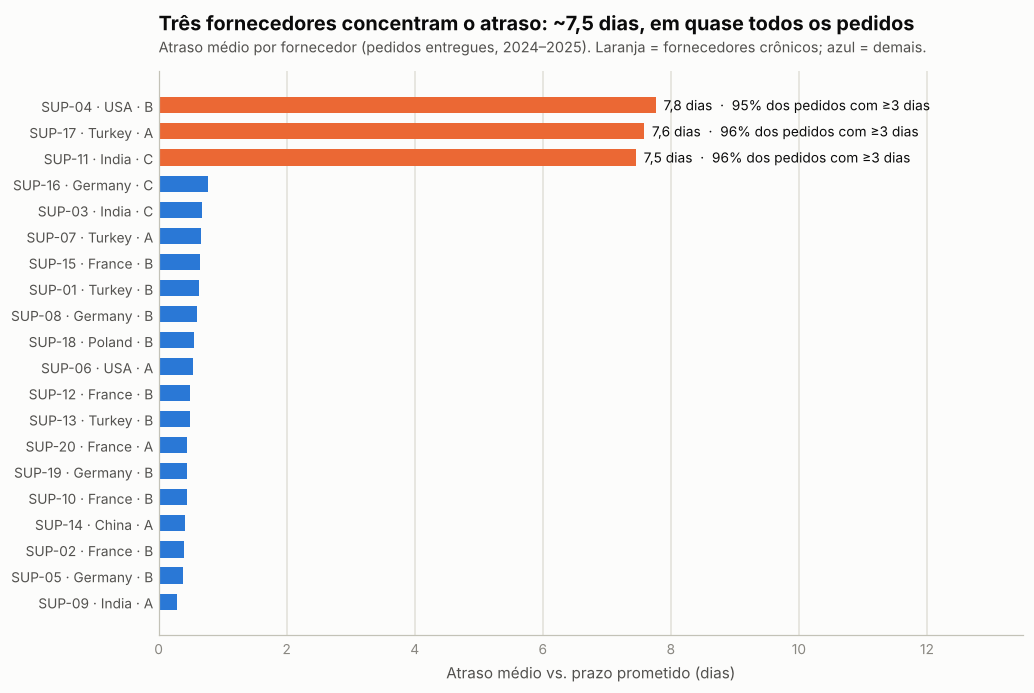

In [9]:
d = forn.sort_values('atraso_medio')
fig, ax = plt.subplots(figsize=(9.5, 6.4))
cor = [ORANGE if i in cronicos else BLUE for i in d.index]
ax.barh(d.rotulo, d.atraso_medio, height=0.62, color=cor)
for (i, row), y in zip(d.iterrows(), range(len(d))):
    if i in cronicos:
        ax.text(row.atraso_medio + 0.12, y, f'{num(row.atraso_medio, 1)} dias  ·  {pct(row.pct_atraso_3d, 0)} dos pedidos com ≥3 dias',
                va='center', fontsize=9, color=INK)
ax.set_xlim(0, 13.5); ax.set_xlabel('Atraso médio vs. prazo prometido (dias)')
ax.tick_params(axis='y', labelcolor=INK2, labelsize=8.5); estilo(ax, 'x')
titulo(ax, 'Três fornecedores concentram o atraso: ~7,5 dias, em quase todos os pedidos',
       'Atraso médio por fornecedor (pedidos entregues, 2024–2025). Laranja = fornecedores crônicos; azul = demais.')
fig.tight_layout(); salvar(fig, 'fig1_atraso_fornecedores'); plt.show()

**Leitura (fato):** existe um **vazio claro** entre dois grupos. Três fornecedores (SUP-04, SUP-17 e SUP-11) atrasam em média ~7,5 dias, com mais de 95% dos pedidos entregues com 3 dias ou mais de atraso. Os outros 17 ficam abaixo de 1 dia em média. O padrão se mantém em **2024 e em 2025** (tabela de persistência acima), então é crônico e não pontual.
Os três pertencem a **tiers diferentes (A, B e C)**: o nível do fornecedor não prevê o atraso.

### A2. O nível do fornecedor prediz qualidade? Ou a rejeição conta outra história?

In [10]:
tier = forn.groupby('tier').agg(fornecedores=('supplier_name', 'size'), rating_medio=('quality_rating', 'mean'),
                                lead_time=('lead_time_days', 'mean'), atraso_medio=('atraso_medio', 'mean'),
                                recebido=('recebido', 'sum'), rejeitado=('rejeitado', 'sum'), share_gasto=('share_gasto', 'sum'))
tier['taxa_rejeicao'] = tier.rejeitado / tier.recebido
display(tier.drop(columns=['recebido', 'rejeitado']).round(4))

rho_q, p_q = stats.spearmanr(forn.quality_rating, forn.taxa_rejeicao)
rho_t, p_t = stats.spearmanr(forn.tier.map({'A': 1, 'B': 2, 'C': 3}), forn.taxa_rejeicao)
rho_l, p_l = stats.spearmanr(forn.quality_rating, forn.atraso_medio)
chi2, p_chi, _, _ = stats.chi2_contingency(np.array([forn.rejeitado, forn.recebido - forn.rejeitado]))
K.update(rej_geral=float(forn.rejeitado.sum() / forn.recebido.sum()), rej_min=float(forn.taxa_rejeicao.min()), rej_max=float(forn.taxa_rejeicao.max()),
         rho_rating_rej=float(rho_q), p_rating_rej=float(p_q), rho_tier_rej=float(rho_t), p_tier_rej=float(p_t),
         rho_rating_atraso=float(rho_l), p_rating_atraso=float(p_l), chi2_p=float(p_chi),
         rating_A=float(tier.rating_medio['A']), rating_C=float(tier.rating_medio['C']),
         rej_A=float(tier.taxa_rejeicao['A']), rej_B=float(tier.taxa_rejeicao['B']), rej_C=float(tier.taxa_rejeicao['C']),
         rating_cron_max=float(max(K['cron_rating'])), rating_top_nome=forn.supplier_name[forn.quality_rating.idxmax()],
         rating_top=float(forn.quality_rating.max()), rating_top_cron=bool(forn.quality_rating.idxmax() in cronicos))
print(f"Rejeição geral {pct(K['rej_geral'], 2)} | entre fornecedores: {pct(K['rej_min'], 2)} a {pct(K['rej_max'], 2)}")
print(f"Spearman rating × rejeição: rho={rho_q:.2f} (p={p_q:.2f}) | tier × rejeição: rho={rho_t:.2f} (p={p_t:.2f}) | rating × atraso: rho={rho_l:.2f} (p={p_l:.2f})")
print(f"Qui-quadrado (taxas de rejeição iguais entre fornecedores?): p={p_chi:.1e}  → a diferença é detectável, porém pequena ({pct(K['rej_min'],2)} a {pct(K['rej_max'],2)})")

,fornecedores,rating_medio,lead_time,atraso_medio,share_gasto,taxa_rejeicao
tier,,,,,,
A,6,4.6867,7.0,1.6549,0.2954,0.0238
B,11,3.9073,18.0,1.1679,0.5418,0.0243
C,3,2.9467,35.0,2.9650,0.1628,0.0246


Rejeição geral 2,42% | entre fornecedores: 2,27% a 2,56%
Spearman rating × rejeição: rho=-0.27 (p=0.25) | tier × rejeição: rho=0.36 (p=0.12) | rating × atraso: rho=-0.09 (p=0.69)
Qui-quadrado (taxas de rejeição iguais entre fornecedores?): p=6.1e-13  → a diferença é detectável, porém pequena (2,27% a 2,56%)


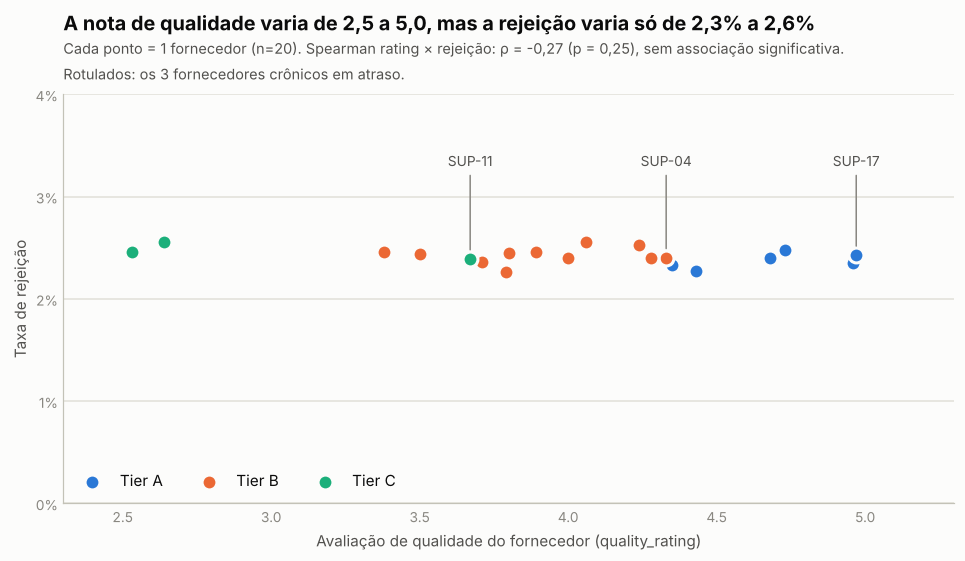

In [11]:
fig, ax = plt.subplots(figsize=(9, 5.2))
CORES_TIER = {'A': BLUE, 'B': ORANGE, 'C': AQUA}
for t in ['A', 'B', 'C']:
    s = forn[forn.tier == t]
    ax.scatter(s.quality_rating, s.taxa_rejeicao * 100, s=95, color=CORES_TIER[t], edgecolor=SURFACE, linewidth=2, label=f'Tier {t}', zorder=3)
for i in cronicos:
    ax.annotate(forn.supplier_name[i], (forn.quality_rating[i], forn.taxa_rejeicao[i] * 100), xytext=(forn.quality_rating[i], 3.3), ha='center', fontsize=9, color=INK2,
                arrowprops=dict(arrowstyle='-', color=MUTED, linewidth=1, shrinkA=2, shrinkB=6))
ax.set_ylim(0, 4); ax.set_xlim(2.3, 5.3); ax.set_yticks([0, 1, 2, 3, 4])
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_xlabel('Avaliação de qualidade do fornecedor (quality_rating)'); ax.set_ylabel('Taxa de rejeição')
ax.legend(title=None, loc='lower left', ncol=3); estilo(ax, 'y')
titulo(ax, 'A nota de qualidade varia de 2,5 a 5,0, mas a rejeição varia só de 2,3% a 2,6%',
       f"Cada ponto = 1 fornecedor (n=20). Spearman rating × rejeição: ρ = {num(rho_q,2)} (p = {num(p_q,2)}), sem associação significativa.\nRotulados: os 3 fornecedores crônicos em atraso.")
fig.tight_layout(); salvar(fig, 'fig2_rating_vs_rejeicao'); plt.show()

**Leitura (fato, associação — não causalidade):**
- O **tier** muda muito a *nota* (média 4,7 no A contra 2,9 no C) e o *lead time* (7 contra 35 dias), mas **quase nada na rejeição** (2,38% no A, 2,43% no B e 2,46% no C).
- A **nota de qualidade não tem associação significativa** com a rejeição nem com o atraso (p > 0,2 em ambos). Com apenas 20 fornecedores, o poder estatístico é baixo, então o resultado é "sem evidência de relação", não "prova de que não há relação".
- A **maior nota do conjunto (4,97) é do SUP-17, justamente um dos três fornecedores crônicos em atraso**. Ou seja, **a nota não captura confiabilidade de entrega**.

Pergunta do case — *"o nível prediz qualidade ou a rejeição conta uma história diferente?"* → **A rejeição conta uma história diferente:** é praticamente uniforme (2,3% a 2,6%) e não acompanha o tier nem a nota. O teste qui-quadrado detecta essa pequena diferença (p < 0,001) apenas por causa do grande volume recebido (~3,9 milhões de unidades), mas ela é de ~0,3 ponto percentual e sem relação com o rating. Já o atraso é o que realmente diferencia os fornecedores.

### A3. Há risco de dependência em fornecedores de fonte única?

In [12]:
ss = forn[forn.is_single_source == 1]
display(ss[['supplier_name', 'country', 'tier', 'quality_rating', 'atraso_medio', 'taxa_rejeicao', 'share_gasto']].round(3))
K['ss_n'] = int(len(ss)); K['ss_share_gasto'] = float(ss.share_gasto.sum()); K['ss_nomes'] = ss.supplier_name.tolist()
K['ss_pior_nome'] = ss.sort_values('quality_rating').supplier_name.iloc[0]; K['ss_pior_rating'] = float(ss.quality_rating.min())
print(f"{len(ss)} de {len(forn)} fornecedores são fonte única e somam {pct(K['ss_share_gasto'])} do gasto. Nenhum é crônico em atraso: {all(i not in cronicos for i in ss.index)}")

# Dependência no nível do PRODUTO: quantos fornecedores distintos já entregaram cada SKU?
ps = linhas_ent.groupby('product_id').agg(fornecedores=('supplier_id', 'nunique'), gasto=('gasto', 'sum'))
ps_ss = linhas_ent[linhas_ent.supplier_id.isin(ss.index)].groupby('product_id').gasto.sum()
ps['share_gasto_fonte_unica'] = (ps_ss / ps.gasto).fillna(0)
print('Fornecedores distintos por SKU (min / mediana / max):', ps.fornecedores.min(), ps.fornecedores.median(), ps.fornecedores.max())
print(f"Maior participação de fontes únicas no gasto de um mesmo SKU: {pct(ps.share_gasto_fonte_unica.max())}")
K['sku_forn_min'] = int(ps.fornecedores.min()); K['sku_ss_max'] = float(ps.share_gasto_fonte_unica.max())

,supplier_name,country,tier,quality_rating,atraso_medio,taxa_rejeicao,share_gasto
supplier_id,,,,,,,
3,SUP-03,India,C,2.53,0.673,0.025,0.057
5,SUP-05,Germany,B,3.79,0.385,0.023,0.045
7,SUP-07,Turkey,A,4.43,0.664,0.023,0.050
12,SUP-12,France,B,3.80,0.493,0.024,0.051
19,SUP-19,Germany,B,4.24,0.442,0.025,0.057


5 de 20 fornecedores são fonte única e somam 26,2% do gasto. Nenhum é crônico em atraso: True
Fornecedores distintos por SKU (min / mediana / max): 20 20.0 20
Maior participação de fontes únicas no gasto de um mesmo SKU: 30,7%


**Leitura:** a flag `is_single_source` marca **5 fornecedores (26% do gasto)**, nenhum deles crônico em atraso. Porém o histórico de compras mostra que **cada SKU foi comprado dos 20 fornecedores**, e nenhum SKU tem mais de ~31% do gasto em fontes únicas. Portanto **os dados não confirmam dependência no nível do produto**. A flag precisa ser entendida (é por fornecedor? por contrato?) antes de virar decisão.
O ponto de atenção concreto é **SUP-03** (fonte única, tier C, nota 2,53, a **pior do conjunto**): é o caso em que um fornecedor de baixa nota e sem alternativa declarada coincidem.

## 10. Análise B — Margem, frete e portfólio

### B1. Qual é a margem por categoria e por SKU?
Margem em **duas camadas**, para não misturar preço de lista, receita realizada e frete (alerta do case):
1. **Margem bruta** = receita − custo padrão dos produtos vendidos;
2. **Margem líquida de frete** = margem bruta − custo de frete.

In [13]:
C = resumo_margem(vendas, 'category').sort_values('ml_pct')
display(C[['category', 'receita', 'cogs', 'frete', 'margem_bruta', 'margem_liquida', 'mb_pct', 'frete_pct', 'ml_pct']].round(3))

P = resumo_margem(vendas, ['product_code', 'category', 'abc_class']).sort_values('ml_pct')
neg = P[P.margem_liquida < 0]
print(f"SKUs com margem líquida negativa: {len(neg)} de {len(P)} → todos Fasteners: {set(neg.category) == {'Fasteners'}}")
display(neg[['product_code', 'receita', 'mb_pct', 'frete_pct', 'ml_pct', 'margem_liquida']].round(3))

f = C[C.category == 'Fasteners'].iloc[0]
K.update(fas_receita=float(f.receita), fas_mb_pct=float(f.mb_pct), fas_frete_pct=float(f.frete_pct), fas_ml_pct=float(f.ml_pct),
         fas_ml=float(f.margem_liquida), fas_share_receita=float(f.receita / K['receita']), fas_unid_share=float(f.unidades / C.unidades.sum()),
         n_sku_neg=int(len(neg)), n_sku=int(len(P)), cat_ml={r.category: float(r.ml_pct) for r in C.itertuples()},
         cat_mb={r.category: float(r.mb_pct) for r in C.itertuples()}, cat_frete={r.category: float(r.frete_pct) for r in C.itertuples()},
         cat_receita={r.category: float(r.receita) for r in C.itertuples()})
K['linhas_ml_neg'] = float((vendas.ml < 0).mean())
print(f"Linhas de venda com margem líquida negativa: {pct(K['linhas_ml_neg'])} | Fasteners: receita {pct(K['fas_share_receita'])} do total")

,category,receita,cogs,frete,margem_bruta,margem_liquida,mb_pct,frete_pct,ml_pct
3,Fasteners,4.578861e+06,2456681.61,5460945.32,2122179.44,-3338765.88,0.463,1.193,-0.729
0,Bearings,2.342476e+07,13935751.36,3075261.93,9489012.91,6413750.98,0.405,0.131,0.274
1,Casings,6.089934e+07,36320096.13,3885057.62,24579247.52,20694189.90,0.404,0.064,0.340
4,Hydraulics,1.515542e+08,88660890.03,4230680.35,62893260.58,58662580.23,0.415,0.028,0.387
2,Electronics,8.677731e+07,47910311.04,4425103.55,38867001.73,34441898.18,0.448,0.051,0.397


SKUs com margem líquida negativa: 8 de 40 → todos Fasteners: True


,product_code,receita,mb_pct,frete_pct,ml_pct,margem_liquida
27,FAS-04,326671.20,0.465,2.317,-1.852,-605127.79
25,FAS-02,527375.79,0.294,2.017,-1.723,-908926.69
29,FAS-06,417163.04,0.493,1.716,-1.223,-510328.20
30,FAS-07,404791.20,0.320,1.284,-0.964,-390297.86
28,FAS-05,742361.36,0.500,1.237,-0.737,-547028.50
26,FAS-03,697066.65,0.510,0.795,-0.285,-198806.98
31,FAS-08,630408.38,0.512,0.673,-0.161,-101799.04
24,FAS-01,833023.43,0.518,0.609,-0.092,-76450.82


Linhas de venda com margem líquida negativa: 14,4% | Fasteners: receita 1,4% do total


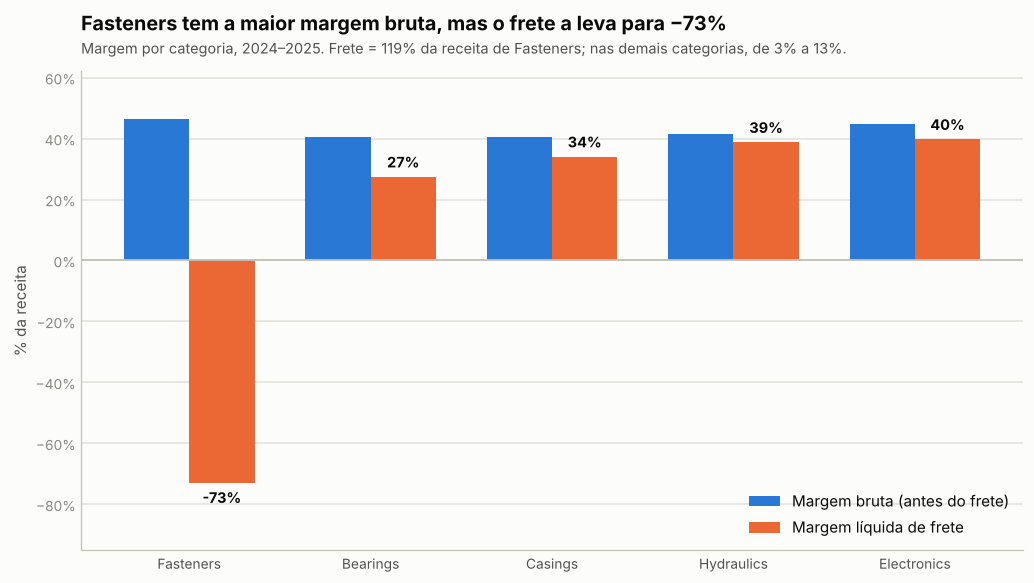

In [14]:
C2 = C.copy(); x = np.arange(len(C2)); w = 0.36
fig, ax = plt.subplots(figsize=(9.5, 5.4))
ax.bar(x - w/2, C2.mb_pct * 100, w, color=BLUE, label='Margem bruta (antes do frete)')
ax.bar(x + w/2, C2.ml_pct * 100, w, color=ORANGE, label='Margem líquida de frete')
for xi, v in zip(x + w/2, C2.ml_pct * 100):
    ax.text(xi, v + (2 if v >= 0 else -2), f'{num(v, 0)}%', ha='center', va='bottom' if v >= 0 else 'top', fontsize=9.5, color=INK, fontweight='bold')
ax.axhline(0, color=AXIS, linewidth=1.2)
ax.set_xticks(x); ax.set_xticklabels(C2.category, color=INK2, fontsize=10)
ax.set_ylim(-95, 62); ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); ax.set_ylabel('% da receita')
ax.legend(loc='lower right'); estilo(ax, 'y')
titulo(ax, 'Fasteners tem a maior margem bruta, mas o frete a leva para −73%',
       'Margem por categoria, 2024–2025. Frete = 119% da receita de Fasteners; nas demais categorias, de 3% a 13%.')
fig.tight_layout(); salvar(fig, 'fig3_margem_categoria'); plt.show()

**Leitura (fato):** a "categoria com margem negativa" que o case anuncia é **Fasteners**, mas **só depois do frete**. Antes dele, Fasteners tem a *maior* margem bruta (46%). O custo do produto não é o problema: é o **frete (119% da receita)**. Os 8 SKUs de Fasteners têm margem líquida negativa; nenhum SKU de outra categoria tem.

### B2. Volume maior compensa margem menor?

In [15]:
rho_v, p_v = stats.spearmanr(P.unidades, P.ml_pct)
K['rho_vol_ml'] = float(rho_v); K['p_vol_ml'] = float(p_v)
u = C.set_index('category')
print(f"Unidades vendidas por categoria: {u.unidades.min():,.0f} a {u.unidades.max():,.0f}  |  Fasteners: {u.unidades['Fasteners']:,.0f} (2º maior volume) com receita de {mi(u.receita['Fasteners'])} mi")
print(f"Spearman volume × margem líquida % (SKUs, n={len(P)}): rho={rho_v:.2f} (p={p_v:.2f})")
K['fas_unid'] = float(u.unidades['Fasteners']); K['unid_min'] = float(u.unidades.min()); K['unid_max'] = float(u.unidades.max())
K['fas_receita_kg'] = float(u.receita['Fasteners'] / u.kg['Fasteners']); K['fas_lucro_kg'] = float(u.margem_bruta['Fasteners'] / u.kg['Fasteners'])
print(f"Fasteners: receita por kg = {num(K['fas_receita_kg'], 2)} | lucro bruto por kg = {num(K['fas_lucro_kg'], 2)}")

Unidades vendidas por categoria: 380,465 a 414,820  |  Fasteners: 400,196 (2º maior volume) com receita de 4,6 mi
Spearman volume × margem líquida % (SKUs, n=40): rho=-0.10 (p=0.53)
Fasteners: receita por kg = 0,71 | lucro bruto por kg = 0,33


**Leitura:** **não.** Fasteners vende volume de unidades semelhante ao das outras categorias (~400 mil), mas cada unidade vale muito menos (preço de lista médio ~11,5 contra 61 a 369 nas outras). **Não há relação significativa entre volume e margem líquida** entre SKUs (ρ ≈ −0,10; p ≈ 0,5). Vender mais unidades de Fasteners aumenta o prejuízo: o problema é **estrutural (custo logístico por kg vs. valor por kg)**, não de escala.

### B3. De onde vem o frete? O papel do modal

In [16]:
M = resumo_margem(vendas, 'modal')
M['share_receita'] = M.receita / M.receita.sum(); M['share_frete'] = M.frete / M.frete.sum()
display(M[['modal', 'receita', 'share_receita', 'frete', 'share_frete', 'frete_pct', 'mb_pct', 'ml_pct']].round(3))
air = M[M.modal == 'Air'].iloc[0]
K.update(air_share_rec=float(air.share_receita), air_share_frete=float(air.share_frete), air_frete_pct=float(air.frete_pct),
         air_ml_pct=float(air.ml_pct), outros_frete_pct_max=float(M[M.modal != 'Air'].frete_pct.max()),
         outros_ml_pct_min=float(M[M.modal != 'Air'].ml_pct.min()), outros_ml_pct_max=float(M[M.modal != 'Air'].ml_pct.max()),
         frete_air=float(air.frete))

# O Air é mais rápido ou mais confiável nos dados?
sh_m = sh.assign(transito=(sh.delivery_date - sh.ship_date).dt.days).merge(car[['carrier_id', 'mode', 'avg_transit_days', 'reliability_score']], on='carrier_id')
srv = sh_m.groupby('mode').agg(remessas=('shipment_id', 'size'), transito_real=('transito', 'mean'), transito_tabela=('avg_transit_days', 'first'),
                               no_prazo=('on_time_flag', 'mean'), avaria=('damaged_flag', 'mean'), confiab_tabela=('reliability_score', 'first'))
display(srv.round(3))
K['transito_real'] = {k: float(v) for k, v in srv.transito_real.items()}; K['no_prazo'] = {k: float(v) for k, v in srv.no_prazo.items()}
K['transito_tab'] = {k: float(v) for k, v in srv.transito_tabela.items()}

# O Air é escolhido por critério (prioridade, contrato, segmento, categoria)?
sh_c = sh_m.merge(cus[['customer_id', 'priority_tier', 'contract_type', 'industry_segment']], on='customer_id')
pv = {}
for col in ['priority_tier', 'contract_type', 'industry_segment']:
    pv[col] = float(stats.chi2_contingency(pd.crosstab(sh_c[col], sh_c['mode']))[1])
K['p_modal_criterio'] = pv
print('Modal depende da prioridade/contrato/segmento do cliente? p-valores qui-quadrado:', {k: round(v, 2) for k, v in pv.items()})
print('Participação do Air nas linhas de venda por categoria:', vendas.groupby('category').modal.apply(lambda s: round((s == 'Air').mean(), 3)).to_dict())

,modal,receita,share_receita,frete,share_frete,frete_pct,mb_pct,ml_pct
0,Air,83176181.96,0.254,16068161.94,0.762,0.193,0.426,0.233
1,Rail,75656262.79,0.231,1509684.22,0.072,0.020,0.417,0.397
2,Road,81641875.49,0.249,2498055.60,0.119,0.031,0.421,0.390
3,Sea,86760112.11,0.265,1001147.01,0.047,0.012,0.422,0.410


,remessas,transito_real,transito_tabela,no_prazo,avaria,confiab_tabela
mode,,,,,,
Air,1125,5.075,1,0.861,0.042,0.92
Rail,1098,4.896,5,0.866,0.039,0.88
Road,1091,4.919,3,0.860,0.042,0.86
Sea,1186,5.184,14,0.848,0.043,0.92


Modal depende da prioridade/contrato/segmento do cliente? p-valores qui-quadrado: {'priority_tier': 0.09, 'contract_type': 0.7, 'industry_segment': 0.53}
Participação do Air nas linhas de venda por categoria: {'Bearings': 0.253, 'Casings': 0.25, 'Electronics': 0.243, 'Fasteners': 0.25, 'Hydraulics': 0.253}


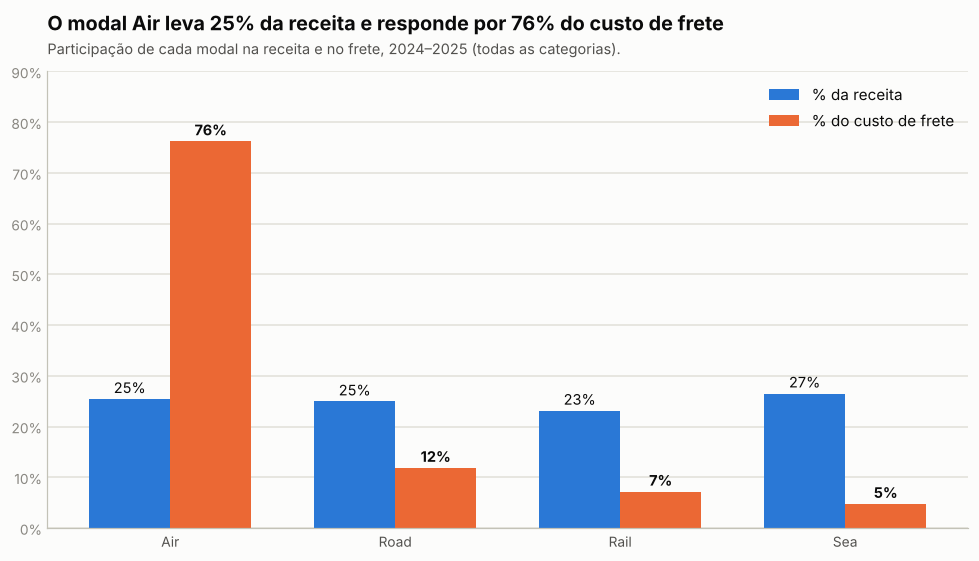

In [17]:
M2 = M.set_index('modal').loc[['Air', 'Road', 'Rail', 'Sea']]; x = np.arange(4); w = 0.36
fig, ax = plt.subplots(figsize=(9, 5.2))
ax.bar(x - w/2, M2.share_receita * 100, w, color=BLUE, label='% da receita')
ax.bar(x + w/2, M2.share_frete * 100, w, color=ORANGE, label='% do custo de frete')
for xi, v in zip(x - w/2, M2.share_receita * 100): ax.text(xi, v + 1.2, f'{num(v, 0)}%', ha='center', fontsize=9.5, color=INK)
for xi, v in zip(x + w/2, M2.share_frete * 100): ax.text(xi, v + 1.2, f'{num(v, 0)}%', ha='center', fontsize=9.5, color=INK, fontweight='bold')
ax.set_xticks(x); ax.set_xticklabels(M2.index, color=INK2, fontsize=10.5)
ax.set_ylim(0, 90); ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); ax.legend(loc='upper right'); estilo(ax, 'y')
titulo(ax, 'O modal Air leva 25% da receita e responde por 76% do custo de frete',
       'Participação de cada modal na receita e no frete, 2024–2025 (todas as categorias).')
fig.tight_layout(); salvar(fig, 'fig4_modal_frete'); plt.show()

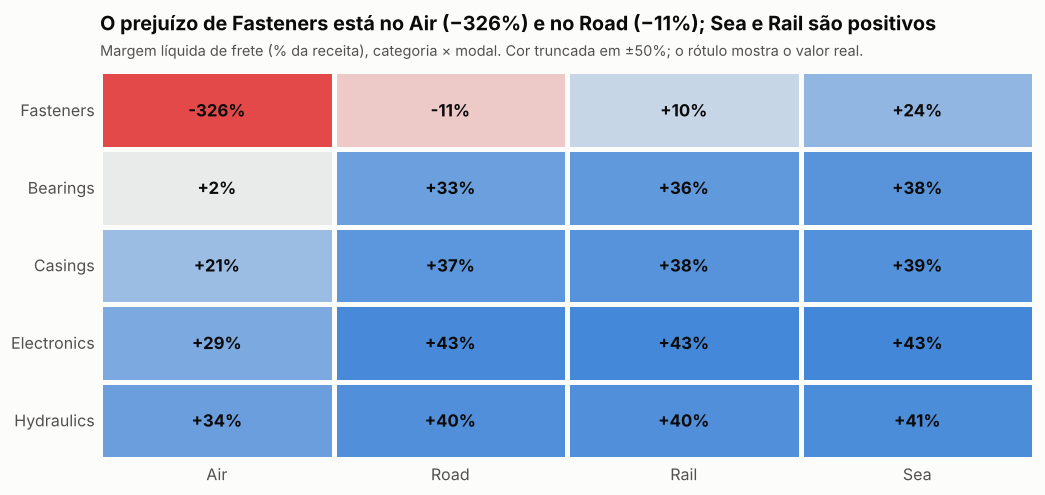

In [18]:
H = vendas.groupby(['category', 'modal']).agg(receita=('revenue', 'sum'), mb=('mb', 'sum'), frete=('freight_cost', 'sum')).reset_index()
H['ml_pct'] = (H.mb - H.frete) / H.receita
mat = H.pivot(index='category', columns='modal', values='ml_pct').loc[['Fasteners', 'Bearings', 'Casings', 'Electronics', 'Hydraulics'], ['Air', 'Road', 'Rail', 'Sea']]
K['mat_ml'] = {c: {m: float(mat.loc[c, m]) for m in mat.columns} for c in mat.index}
lab = mat.map(lambda v: f'{v*100:+.0f}%') if hasattr(mat, 'map') else mat.applymap(lambda v: f'{v*100:+.0f}%')
fig, ax = plt.subplots(figsize=(9.6, 4.6))
sns.heatmap(mat.clip(-0.5, 0.5), annot=lab, fmt='', cmap=CMAP_DIV, center=0, vmin=-0.5, vmax=0.5, cbar=False, linewidths=3, linecolor=SURFACE,
            annot_kws={'fontsize': 11, 'fontweight': 'bold', 'color': INK}, ax=ax)
ax.set_xlabel(''); ax.set_ylabel(''); ax.tick_params(length=0, labelsize=10.5, labelcolor=INK2)
titulo(ax, 'O prejuízo de Fasteners está no Air (−326%) e no Road (−11%); Sea e Rail são positivos',
       'Margem líquida de frete (% da receita), categoria × modal. Cor truncada em ±50%; o rótulo mostra o valor real.')
fig.tight_layout(); salvar(fig, 'fig5_heatmap_categoria_modal'); plt.show()

**Leitura (fato):**
- O **Air** transporta 25% da receita, mas gera **76% do custo de frete** (19% da receita contra 1% a 3% nos outros modais). A margem líquida cai para 23% no Air, contra 39% a 41% nos demais.
- **O Air não entrega mais rápido nem mais confiável nos dados:** o trânsito real é ~5 dias em todos os modais, e o percentual no prazo fica em ~85% a 87% para todos (a tabela `carrier` diz 1 dia para o Air e 14 para o Sea). Isso contradiz o dicionário, então precisa ser **investigado antes de decidir** (limitação registrada).
- **A escolha do modal não parece seguir critério comercial:** não há relação significativa com prioridade, contrato ou segmento do cliente (p > 0,05), e cada categoria usa o Air em ~25% das linhas. Ou seja, itens baratos e pesados vão de Air com a mesma frequência que itens valiosos. *(Isso é um padrão observado; a causa, por exemplo ausência de regra de roteirização, é hipótese.)*

### B4. Simulação: quanto a margem melhoraria com outra regra de modal? (hipótese)
O frete real é muito aderente a `kg × tarifa do modal` (correlação ≈ 0,99, fator mediano ≈ 1,05), então dá para simular o custo em outro modal. **É uma simulação, não um fato:** ignora prazo de entrega, capacidade e nível de serviço.

In [19]:
vendas['frete_modelo'] = vendas.kg * vendas.cost_per_kg
fator = (vendas.freight_cost / vendas.frete_modelo).groupby(vendas.modal).median()   # calibração por modal
K['corr_frete_modelo'] = float(np.corrcoef(vendas.freight_cost, vendas.frete_modelo)[0, 1])
print('Aderência frete real × (kg × tarifa): corr =', round(K['corr_frete_modelo'], 3), '| fator mediano por modal:', fator.round(3).to_dict())

tarifa = car.set_index('mode').cost_per_kg
def simular(destino, categorias=None):
    v = vendas.copy()
    alvo = (v.modal == 'Air') & (v.category.isin(categorias) if categorias else True)
    novo = v.kg * tarifa[destino] * fator[destino]
    v['frete_sim'] = np.where(alvo, novo, v.freight_cost)
    ml = (v.mb.sum() - v.frete_sim.sum()) / v.revenue.sum()
    fas = v[v.category == 'Fasteners']; ml_fas = (fas.mb.sum() - fas.frete_sim.sum()) / fas.revenue.sum()
    return {'economia_frete': v.freight_cost.sum() - v.frete_sim.sum(), 'ml_pct': ml, 'ml_fasteners': ml_fas}

cen = []
for destino in ['Road', 'Rail', 'Sea']:
    for nome, cats in [('Todo o Air', None), ('Só Fasteners e Bearings', ['Fasteners', 'Bearings'])]:
        s = simular(destino, cats); cen.append({'cenario': f'{nome} → {destino}', **s})
cen = pd.DataFrame(cen)
cen['economia_pct_frete'] = cen.economia_frete / vendas.freight_cost.sum()
base = {'cenario': 'Situação atual', 'economia_frete': 0.0, 'ml_pct': K['ml_pct'], 'ml_fasteners': K['fas_ml_pct'], 'economia_pct_frete': 0.0}
cen = pd.concat([pd.DataFrame([base]), cen], ignore_index=True)
display(cen.assign(economia_frete=lambda d: d.economia_frete / 1e6).round(3).rename(columns={'economia_frete': 'economia_frete_mi'}))
K['cenarios'] = cen.to_dict('records')

# ponto de equilíbrio de Fasteners por modal (lucro bruto por kg vs frete por kg)
be = pd.DataFrame({'frete_por_kg': (tarifa * fator).round(3)}).loc[['Air', 'Road', 'Rail', 'Sea']]
be['lucro_bruto_kg_fasteners'] = round(K['fas_lucro_kg'], 3); be['sobra_por_kg'] = (be.lucro_bruto_kg_fasteners - be.frete_por_kg).round(3)
be['viavel'] = be.sobra_por_kg > 0; display(be)
K['breakeven'] = be.reset_index().to_dict('records')

Aderência frete real × (kg × tarifa): corr = 0.988 | fator mediano por modal: {'Air': 1.05, 'Rail': 1.045, 'Road': 1.05, 'Sea': 1.054}


,cenario,economia_frete_mi,ml_pct,ml_fasteners,economia_pct_frete
0,Situação atual,0.000,0.357,-0.729,0.000
1,Todo o Air → Road,13.498,0.398,0.022,0.640
2,Só Fasteners e Bearings → Road,5.391,0.374,0.022,0.256
3,Todo o Air → Rail,14.468,0.401,0.076,0.686
4,Só Fasteners e Bearings → Rail,5.784,0.375,0.076,0.274
5,Todo o Air → Sea,15.100,0.403,0.112,0.716
6,Só Fasteners e Bearings → Sea,6.039,0.376,0.112,0.287


,frete_por_kg,lucro_bruto_kg_fasteners,sobra_por_kg,viavel
mode,,,,
Air,2.624,0.33,-2.294,False
Road,0.420,0.33,-0.090,False
Rail,0.261,0.33,0.069,True
Sea,0.158,0.33,0.172,True


**Leitura:** em Fasteners, **cada kg gera apenas ~0,33 de lucro bruto**. Um kg despachado por Road custa ~0,42 e por Air ~2,6, então **qualquer envio por Air ou Road dá prejuízo por construção**. Só **Rail (~0,26/kg) e Sea (~0,16/kg)** deixam sobra, e no Rail ela é pequena (+0,07 por kg), então vale priorizar o Sea quando o prazo permitir. O cenário "Só Fasteners e Bearings: Air → Sea/Rail" mostra o ganho de uma mudança **pontual** (as duas categorias onde o frete pesa mais), e o "Todo o Air → …" mostra o teto teórico. Antes de aplicar, é preciso checar o prazo exigido por cada cliente, porque o dataset não permite validar o ganho de velocidade do Air.

## 11. Análise C — Sazonalidade e estoque

### C1. A queda de agosto e o pico do 4º trimestre aparecem em todos os segmentos?
Demanda = unidades expedidas por mês (`ship_date`).

Agosto vs média dos demais meses: -38,2% | Q4 vs média dos demais meses: 45,7%
2024: ago -40,5%, Q4 48,4% | 2025: ago -36,0%, Q4 43,0%


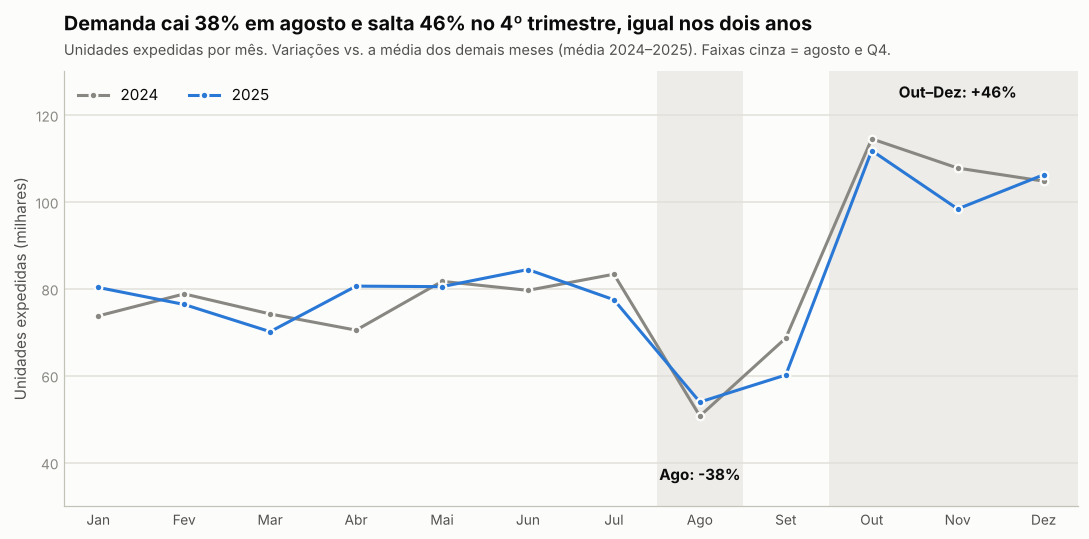

In [20]:
mes_ano = vendas.groupby(['ano', 'mes']).agg(unidades=('qty_shipped', 'sum'), receita=('revenue', 'sum')).reset_index()
piv = mes_ano.pivot(index='mes', columns='ano', values='unidades')
media_mes = piv.mean(axis=1)
ago_vs = media_mes[8] / media_mes.drop(8).mean() - 1
q4_vs = media_mes[[10, 11, 12]].mean() / media_mes.drop([10, 11, 12]).mean() - 1
K.update(ago_vs=float(ago_vs), q4_vs=float(q4_vs), ago_24=float(piv.loc[8, 2024] / piv.drop(8).loc[:, 2024].mean() - 1),
         ago_25=float(piv.loc[8, 2025] / piv.drop(8).loc[:, 2025].mean() - 1),
         q4_24=float(piv.loc[[10, 11, 12], 2024].mean() / piv.drop([10, 11, 12]).loc[:, 2024].mean() - 1),
         q4_25=float(piv.loc[[10, 11, 12], 2025].mean() / piv.drop([10, 11, 12]).loc[:, 2025].mean() - 1))
print(f"Agosto vs média dos demais meses: {pct(ago_vs)} | Q4 vs média dos demais meses: {pct(q4_vs)}")
print(f"2024: ago {pct(K['ago_24'])}, Q4 {pct(K['q4_24'])} | 2025: ago {pct(K['ago_25'])}, Q4 {pct(K['q4_25'])}")

fig, ax = plt.subplots(figsize=(10, 5))
xs = np.arange(1, 13)
for m0, m1 in [(7.5, 8.5), (9.5, 12.5)]: ax.axvspan(m0, m1, color=GRID, alpha=0.55, linewidth=0)
ax.plot(xs, piv[2024] / 1e3, color=MUTED, linewidth=2, marker='o', markersize=5, markeredgecolor=SURFACE, markeredgewidth=1.5, label='2024')
ax.plot(xs, piv[2025] / 1e3, color=BLUE, linewidth=2, marker='o', markersize=5, markeredgecolor=SURFACE, markeredgewidth=1.5, label='2025')
ax.text(8, 36, f'Ago: {pct(ago_vs, 0)}', fontsize=10, fontweight='bold', color=INK, ha='center')
ax.text(11, 124, f'Out–Dez: +{num(q4_vs*100, 0)}%', fontsize=10, fontweight='bold', color=INK, ha='center')
ax.set_xticks(xs); ax.set_xticklabels(MESES, color=INK2); ax.set_ylim(30, 130); ax.set_xlim(0.6, 12.4)
ax.set_ylabel('Unidades expedidas (milhares)'); ax.legend(loc='upper left', ncol=2); estilo(ax, 'y')
titulo(ax, 'Demanda cai 38% em agosto e salta 46% no 4º trimestre, igual nos dois anos',
       'Unidades expedidas por mês. Variações vs. a média dos demais meses (média 2024–2025). Faixas cinza = agosto e Q4.')
fig.tight_layout(); salvar(fig, 'fig6_sazonalidade'); plt.show()

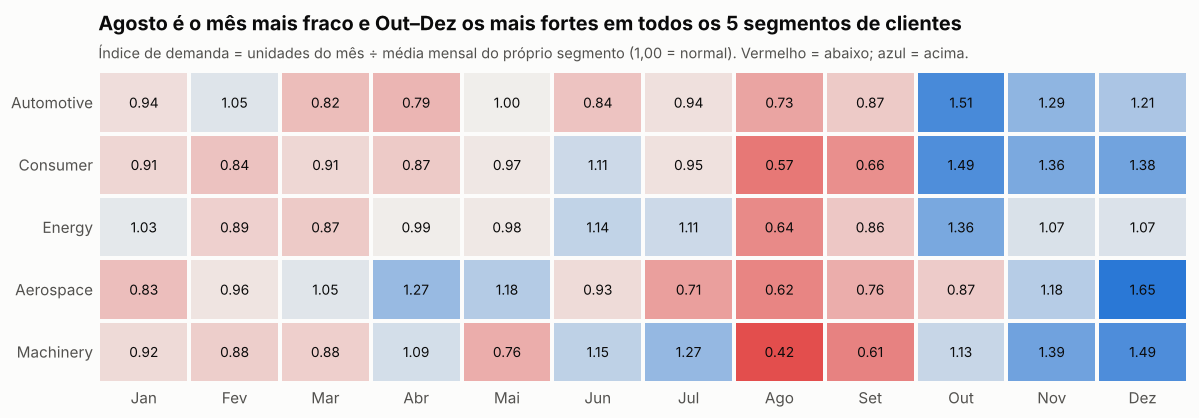

mes,1,2,3,4,5,6,7,8,9,10,11,12
remessas,377.0,367.0,363.0,356.0,393.0,398.0,387.0,417.0,329.0,384.0,353.0,376.0
unid_por_remessa,409.0,423.0,398.0,424.0,413.0,412.0,416.0,251.0,392.0,589.0,584.0,561.0


In [21]:
seg = vendas.groupby(['industry_segment', 'mes']).qty_shipped.sum().unstack()
idx_seg = seg.div(seg.mean(axis=1), axis=0)
idx_seg['Q4'] = idx_seg[[10, 11, 12]].mean(axis=1)
cat_ = vendas.groupby(['category', 'mes']).qty_shipped.sum().unstack(); idx_cat = cat_.div(cat_.mean(axis=1), axis=0)
idx_cat['Q4'] = idx_cat[[10, 11, 12]].mean(axis=1)
K['idx_ago_seg'] = {k: float(v) for k, v in idx_seg[8].items()}; K['idx_q4_seg'] = {k: float(v) for k, v in idx_seg['Q4'].items()}
K['idx_ago_cat_range'] = [float(idx_cat[8].min()), float(idx_cat[8].max())]; K['idx_q4_cat_range'] = [float(idx_cat['Q4'].min()), float(idx_cat['Q4'].max())]

ordem = ['Automotive', 'Consumer', 'Energy', 'Aerospace', 'Machinery']
hm = idx_seg.loc[ordem, list(range(1, 13))]; hm.columns = MESES
fig, ax = plt.subplots(figsize=(11, 3.9))
sns.heatmap(hm, annot=True, fmt='.2f', cmap=CMAP_DIV, center=1.0, vmin=0.4, vmax=1.6, cbar=False, linewidths=2.5, linecolor=SURFACE,
            annot_kws={'fontsize': 9, 'color': INK}, ax=ax)
ax.set_xlabel(''); ax.set_ylabel(''); ax.tick_params(length=0, labelsize=10, labelcolor=INK2)
titulo(ax, 'Agosto é o mês mais fraco e Out–Dez os mais fortes em todos os 5 segmentos de clientes',
       'Índice de demanda = unidades do mês ÷ média mensal do próprio segmento (1,00 = normal). Vermelho = abaixo; azul = acima.')
fig.tight_layout(); salvar(fig, 'fig7_sazonalidade_segmentos'); plt.show()

# A queda de agosto é menos remessas ou remessas menores?
rem = vendas.groupby(['mes', 'shipment_id']).qty_shipped.sum().groupby('mes').agg(['size', 'mean']).rename(columns={'size': 'remessas', 'mean': 'unid_por_remessa'})
display(rem.round(0).T)
K['unid_rem_ago'] = float(rem.unid_por_remessa[8]); K['unid_rem_med'] = float(rem.unid_por_remessa.drop([8, 10, 11, 12]).mean())
K['unid_rem_q4'] = float(rem.unid_por_remessa[[10, 11, 12]].mean()); K['rem_ago'] = int(rem.remessas[8]); K['rem_med'] = float(rem.remessas.mean())

**Leitura (fato):** a sazonalidade é **estrutural e igual nos dois anos** (ago −38% e Q4 +46% na média; 2024 e 2025 são muito parecidos) e aparece em **todos os 5 segmentos** (índice de agosto entre 0,42 e 0,73) e **em todas as 5 categorias**. Um detalhe relevante: **o número de remessas em agosto não cai** (foi, na verdade, o maior do ano). O que cai é o **tamanho de cada remessa** (~250 unidades contra ~410 no resto do ano; ~580 no Q4). A demanda sazonal se manifesta em **pedidos menores/maiores**, não em mais ou menos clientes comprando. No agregado anual, as unidades ficam estáveis entre 2024 e 2025 (−0,8%) e a receita sobe 4,6%.

### C2. Como as rupturas se relacionam com a demanda sazonal?
Cada snapshot é uma **foto semanal**; calculo a **proporção de snapshots** em ruptura ou abaixo do ponto de reposição (nunca somas entre semanas).

Ponto de reposição constante em todos os armazém×produto nos 24 meses: True


pct_ruptura  pct_abaixo  estoque_medio    unidades
ano  tri                                                    
2024 1          0.020       0.104       1959.920   75586.333
     2          0.042       0.156       1886.801   77270.667
     3          0.040       0.180       1838.560   67572.000
     4          0.069       0.198       1820.529  109013.000
2025 1          0.058       0.198       1758.000   75601.667
     2          0.047       0.202       1717.464   81838.333
     3          0.044       0.198       1747.100   63853.000
     4          0.075       0.241       1742.378  105467.333

Snapshots abaixo do ponto de reposição: 18,4% | em ruptura (estoque = 0): 4,9%
Estoque médio por SKU×armazém: jan/24 2.009 → 2025 1.741 (queda de 13%); Q4 1.781 vs Q3 1.793: sem formação de estoque antes do pico
Ruptura: Q4 7,2% vs Q3 4,2% | abaixo do ROP: Q4 22,0% vs Q3 18,9%  (médias de 2024 e 2025)
Spearman demanda mensal × % ruptura: bruto rho=0.55 (p=0.005) | sem tendência rho=0.60 (p=0.002)   [n=24 meses]
Spearman demanda mensal × % abaixo do ROP: bruto rho=0.47 (p=0.020) | sem tendência rho=0.31 (p=0.142)


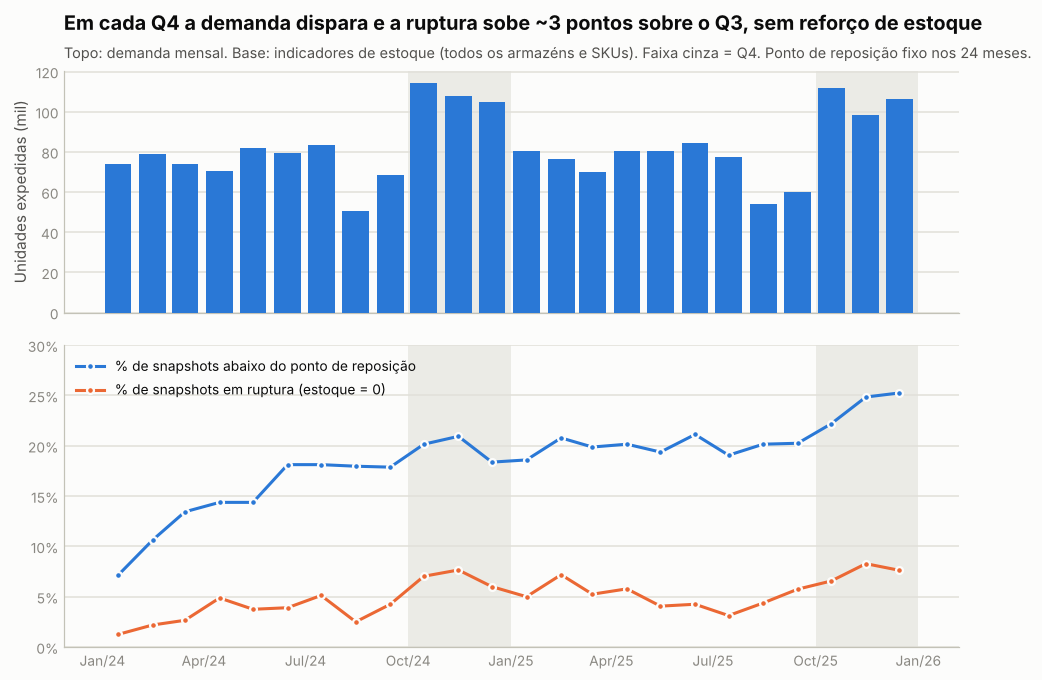

In [22]:
inv['ym'] = inv.snapshot_date.dt.to_period('M')
est_m = inv.groupby('ym').agg(pct_ruptura=('ruptura', 'mean'), pct_abaixo=('abaixo_rop', 'mean'), estoque_medio=('units_on_hand', 'mean')).reset_index()
dem_m = vendas.assign(ym=vendas.ship_date.dt.to_period('M')).groupby('ym').qty_shipped.sum().rename('unidades').reset_index()
em = est_m.merge(dem_m, on='ym'); em['data'] = em.ym.dt.to_timestamp(); em['t'] = range(len(em))
em['mes'] = em.ym.dt.month; em['ano'] = em.ym.dt.year

# O ponto de reposição muda ao longo do tempo? (se for constante, a política é estática)
rop_unico = inv.groupby(['warehouse_id', 'product_id']).reorder_point.nunique()
K['rop_estatico'] = bool((rop_unico == 1).all())
print('Ponto de reposição constante em todos os armazém×produto nos 24 meses:', K['rop_estatico'])

# Tendência geral: o nível sobe ao longo de 2024 (estoque inicial alto sendo consumido). Por isso comparo cada Q4 com o Q3 do MESMO ano.
K['oh_jan24'] = float(em.estoque_medio.iloc[0]); K['oh_2025'] = float(em[em.ano == 2025].estoque_medio.mean())
tri = em.assign(tri=em.mes.sub(1).floordiv(3) + 1).groupby(['ano', 'tri'])[['pct_ruptura', 'pct_abaixo', 'estoque_medio', 'unidades']].mean()
display(tri.round(3))
q3 = tri.xs(3, level='tri'); q4 = tri.xs(4, level='tri')
K['ruptura_q3'] = float(q3.pct_ruptura.mean()); K['ruptura_q4'] = float(q4.pct_ruptura.mean())
K['abaixo_q3'] = float(q3.pct_abaixo.mean()); K['abaixo_q4'] = float(q4.pct_abaixo.mean())
K['estoque_q3'] = float(q3.estoque_medio.mean()); K['estoque_q4'] = float(q4.estoque_medio.mean())
K['ruptura_q4_menos_q3_por_ano'] = {int(a): float(q4.pct_ruptura[a] - q3.pct_ruptura[a]) for a in q4.index}
K['abaixo_q4_menos_q3_por_ano'] = {int(a): float(q4.pct_abaixo[a] - q3.pct_abaixo[a]) for a in q4.index}
K['abaixo_geral'] = float(inv.abaixo_rop.mean()); K['ruptura_geral'] = float(inv.ruptura.mean())

def destend(y):
    c = np.polyfit(em.t, y, 1); return y - np.polyval(c, em.t)
r1 = stats.spearmanr(em.unidades, em.pct_ruptura); r2 = stats.spearmanr(em.unidades, em.pct_abaixo)
d1 = stats.spearmanr(em.unidades, destend(em.pct_ruptura)); d2 = stats.spearmanr(em.unidades, destend(em.pct_abaixo))
K.update(rho_dem_rupt=float(r1[0]), p_dem_rupt=float(r1[1]), rho_dem_abaixo=float(r2[0]), p_dem_abaixo=float(r2[1]),
         rho_dem_rupt_dt=float(d1[0]), p_dem_rupt_dt=float(d1[1]), rho_dem_abaixo_dt=float(d2[0]), p_dem_abaixo_dt=float(d2[1]))
print(f"Snapshots abaixo do ponto de reposição: {pct(K['abaixo_geral'])} | em ruptura (estoque = 0): {pct(K['ruptura_geral'])}")
print(f"Estoque médio por SKU×armazém: jan/24 {num(K['oh_jan24'])} → 2025 {num(K['oh_2025'])} (queda de {pct(1 - K['oh_2025'] / K['oh_jan24'], 0)}); Q4 {num(K['estoque_q4'])} vs Q3 {num(K['estoque_q3'])}: sem formação de estoque antes do pico")
print(f"Ruptura: Q4 {pct(K['ruptura_q4'])} vs Q3 {pct(K['ruptura_q3'])} | abaixo do ROP: Q4 {pct(K['abaixo_q4'])} vs Q3 {pct(K['abaixo_q3'])}  (médias de 2024 e 2025)")
print(f"Spearman demanda mensal × % ruptura: bruto rho={r1[0]:.2f} (p={r1[1]:.3f}) | sem tendência rho={d1[0]:.2f} (p={d1[1]:.3f})   [n=24 meses]")
print(f"Spearman demanda mensal × % abaixo do ROP: bruto rho={r2[0]:.2f} (p={r2[1]:.3f}) | sem tendência rho={d2[0]:.2f} (p={d2[1]:.3f})")

em['x'] = em.data + pd.Timedelta(days=14)          # centro do mês
fig, (a1, a2) = plt.subplots(2, 1, figsize=(10.5, 6.8), sharex=True, gridspec_kw={'height_ratios': [1, 1.25], 'hspace': 0.12})
for a in (a1, a2):
    for ano_ in (2024, 2025): a.axvspan(pd.Timestamp(f'{ano_}-10-01'), pd.Timestamp(f'{ano_+1}-01-01'), color=GRID, alpha=0.6, linewidth=0, zorder=0)
a1.bar(em.x, em.unidades / 1e3, width=24, color=BLUE, zorder=3)
a1.set_ylabel('Unidades expedidas (mil)'); estilo(a1, 'y')
a2.plot(em.x, em.pct_abaixo * 100, color=BLUE, linewidth=2, marker='o', markersize=4.5, markeredgecolor=SURFACE, markeredgewidth=1.5, label='% de snapshots abaixo do ponto de reposição', zorder=3)
a2.plot(em.x, em.pct_ruptura * 100, color=ORANGE, linewidth=2, marker='o', markersize=4.5, markeredgecolor=SURFACE, markeredgewidth=1.5, label='% de snapshots em ruptura (estoque = 0)', zorder=3)
a2.set_ylim(0, 30); a2.set_yticks([0, 5, 10, 15, 20, 25, 30]); a2.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
a2.legend(loc='upper left', fontsize=9); estilo(a2, 'y')
a2.xaxis.set_major_locator(plt.matplotlib.dates.MonthLocator(bymonth=[1, 4, 7, 10])); a2.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%b/%y'))
titulo(a1, f"Em cada Q4 a demanda dispara e a ruptura sobe ~{num((K['ruptura_q4'] - K['ruptura_q3']) * 100, 0)} pontos sobre o Q3, sem reforço de estoque",
       'Topo: demanda mensal. Base: indicadores de estoque (todos os armazéns e SKUs). Faixa cinza = Q4. Ponto de reposição fixo nos 24 meses.')
fig.tight_layout(); salvar(fig, 'fig8_estoque_vs_demanda'); plt.show()

**Leitura (fato + cautela):**
- **[FATO] O ponto de reposição é fixo:** o mesmo valor por armazém × produto nos 24 meses. A política de reposição não muda com a sazonalidade.
- **[FATO] O estoque não se reforça antes do pico:** o estoque médio por SKU×armazém no Q4 é igual ou menor que o do Q3 (ver saída acima).
- **[FATO] A ruptura sobe ~3 pontos percentuais em cada Q4** sobre o Q3 do mesmo ano (7,2% contra 4,2% em média; +2,9 p.p. em 2024 e +3,1 p.p. em 2025).
- **Atenção à tendência:** o nível geral de itens abaixo do ponto de reposição sobe de ~10% (1º tri/24) para ~18–20% a partir do 3º tri/24, enquanto o estoque médio cai ~13% (de ~2.000 em jan/24 para ~1.740 em 2025). Parece consumo do estoque inicial. **Essa rampa de 2024, e não a sazonalidade, explica a subida inicial**, por isso a comparação justa é **Q4 contra Q3 do mesmo ano** e não contra "os demais meses".
- **Associação com a demanda (24 meses):** demanda × ruptura é forte e **resiste a retirar a tendência** (ρ = 0,55, p = 0,005; sem tendência ρ = 0,60, p = 0,002). Já demanda × "abaixo do ponto de reposição" é de ρ = 0,47 (p = 0,02), mas **sem tendência cai para ρ = 0,31 (p = 0,14) e deixa de ser significativa**: para esse indicador o dataset não separa sazonalidade de tendência. Por serem séries temporais (meses vizinhos se parecem) e n = 24, os p-valores devem ser lidos com cautela.

É uma **associação**: o dataset não prova que a demanda *causou* a ruptura, mas o padrão (ponto de reposição fixo, estoque sem reforço, ruptura que sobe a cada Q4) é consistente com uma **reposição que não antecipa a sazonalidade**.

### C3. Quais categorias e SKUs ficam mais vezes abaixo do ponto de reposição?

,pct_abaixo,pct_ruptura
category,,
Hydraulics,0.328,0.062
Electronics,0.188,0.033
Casings,0.145,0.037
Fasteners,0.139,0.065
Bearings,0.121,0.050


,pct_abaixo,pct_ruptura
abc_class,,
A,0.107,0.029
B,0.213,0.061
C,0.219,0.057


,pct_abaixo,pct_ruptura
warehouse_id,,
1,0.217,0.058
2,0.148,0.048
3,0.172,0.038
4,0.199,0.054


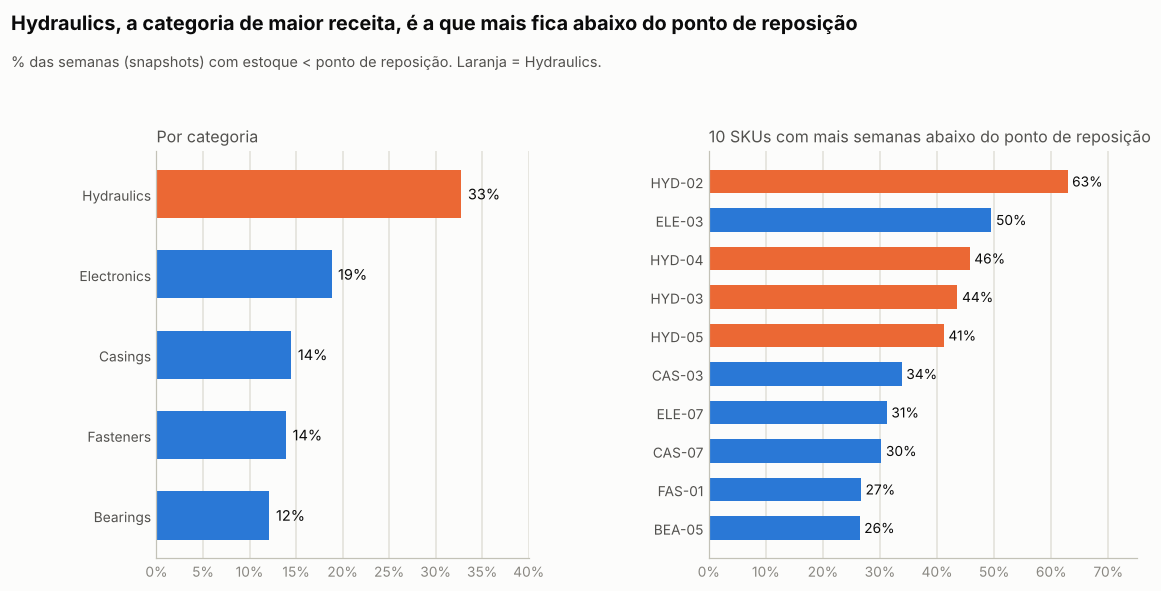

In [23]:
por_cat = inv.groupby('category').agg(pct_abaixo=('abaixo_rop', 'mean'), pct_ruptura=('ruptura', 'mean')).sort_values('pct_abaixo', ascending=False)
por_abc = inv.groupby('abc_class').agg(pct_abaixo=('abaixo_rop', 'mean'), pct_ruptura=('ruptura', 'mean'))
por_sku = inv.groupby(['product_code', 'category']).agg(pct_abaixo=('abaixo_rop', 'mean'), pct_ruptura=('ruptura', 'mean')).reset_index().sort_values('pct_abaixo', ascending=False)
por_wh = inv.groupby('warehouse_id').agg(pct_abaixo=('abaixo_rop', 'mean'), pct_ruptura=('ruptura', 'mean'))
display(por_cat.round(3)); display(por_abc.round(3)); display(por_wh.round(3))
K.update(abaixo_cat={k: float(v) for k, v in por_cat.pct_abaixo.items()}, abaixo_abc={k: float(v) for k, v in por_abc.pct_abaixo.items()},
         top_sku=por_sku.head(5)[['product_code', 'pct_abaixo', 'pct_ruptura']].to_dict('records'),
         hyd_receita_share=float(K['cat_receita']['Hydraulics'] / K['receita']))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.5, 4.8), gridspec_kw={'width_ratios': [1, 1.15], 'wspace': 0.45})
d1 = por_cat.sort_values('pct_abaixo')
a1.barh(d1.index, d1.pct_abaixo * 100, height=0.6, color=[ORANGE if c == 'Hydraulics' else BLUE for c in d1.index])
for y, v in enumerate(d1.pct_abaixo * 100): a1.text(v + 0.7, y, f'{num(v, 0)}%', va='center', fontsize=9.5, color=INK)
a1.set_xlim(0, 40); a1.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); a1.tick_params(axis='y', labelcolor=INK2, labelsize=10)
estilo(a1, 'x'); a1.set_title('Por categoria', loc='left', fontsize=10.5, color=INK2)
d2 = por_sku.head(10).iloc[::-1]
a2.barh(d2.product_code, d2.pct_abaixo * 100, height=0.6, color=[ORANGE if c == 'Hydraulics' else BLUE for c in d2.category])
for y, v in enumerate(d2.pct_abaixo * 100): a2.text(v + 0.8, y, f'{num(v, 0)}%', va='center', fontsize=9, color=INK)
a2.set_xlim(0, 75); a2.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); a2.tick_params(axis='y', labelcolor=INK2, labelsize=9.5)
estilo(a2, 'x'); a2.set_title('10 SKUs com mais semanas abaixo do ponto de reposição', loc='left', fontsize=10.5, color=INK2)
fig.text(0.01, 1.11, 'Hydraulics, a categoria de maior receita, é a que mais fica abaixo do ponto de reposição', fontsize=13, fontweight='bold', ha='left', color=INK)
fig.text(0.01, 1.04, '% das semanas (snapshots) com estoque < ponto de reposição. Laranja = Hydraulics.', fontsize=9.5, color=INK2, ha='left')
salvar(fig, 'fig9_abaixo_rop'); plt.show()

**Leitura (fato):** **Hydraulics está abaixo do ponto de reposição em ~33% das semanas**, mais que o dobro de Bearings (12%) e Casings (~14%), e responde por quase **metade da receita**. Hydraulics ocupa 4 dos 5 SKUs com mais semanas abaixo do ponto de reposição, com HYD-02 chegando a 63%. A classe **A** (mais relevante) está melhor protegida (11% abaixo do ponto de reposição, contra ~21% nas classes B e C), o que indica que a priorização por ABC existe, mas **não protege os SKUs de maior valor de Hydraulics**.

### C4. Existe excesso de estoque simultâneo em outros armazéns?
Em cada semana e produto, comparo o **déficit** dos armazéns abaixo do ponto de reposição com o **excedente** dos demais (estoque acima de *k* × ponto de reposição). O parâmetro *k* é arbitrário, então testo vários valores (análise de sensibilidade).

In [24]:
g = inv.copy()
g['deficit'] = (g.reorder_point - g.units_on_hand).clip(lower=0)
alinhado = inv.groupby(['snapshot_date', 'product_id']).size()
print('Armazéns por semana×produto (esperado 4 em todas):', alinhado.unique())

linhas = []
for k in [2, 3, 5]:
    g['excedente'] = (g.units_on_hand - k * g.reorder_point).clip(lower=0)
    s = g.groupby(['snapshot_date', 'product_id']).agg(deficit=('deficit', 'sum'), excedente=('excedente', 'sum'), falta=('abaixo_rop', 'any'))
    c = s[s.deficit > 0]
    linhas.append({'k (excedente = estoque > k × ROP)': k,
                   '% das semanas-produto com falta em ≥1 armazém': float(s.falta.mean()),
                   '% dessas com excedente em outro armazém': float((c.excedente > 0).mean()),
                   '% do déficit coberto só por transferência': float(np.minimum(c.deficit, c.excedente).sum() / c.deficit.sum())})
reb = pd.DataFrame(linhas)
display(reb.round(3))
K['reb'] = reb.to_dict('records')

Armazéns por semana×produto (esperado 4 em todas): [4]


,k (excedente = estoque > k × ROP),% das semanas-produto com falta em ≥1 armazém,% dessas com excedente em outro armazém,% do déficit coberto só por transferência
0,2,0.52,0.917,0.756
1,3,0.52,0.826,0.627
2,5,0.52,0.590,0.312


**Leitura (fato + hipótese):** em **~52% das semanas-produto algum armazém está abaixo do ponto de reposição**, e na grande maioria delas **outro armazém tem estoque sobrando**. Com *k* = 3, em ~83% dos casos existe excedente. **A conclusão qualitativa se mantém para todos os *k* testados** (59% a 92% dos casos), mas **a magnitude depende de *k***: o déficit coberto só por transferência vai de ~31% (k = 5) a ~76% (k = 2), e ~63% com k = 3 (ver a tabela). Sem comprar nada, **uma parte substancial do déficit** poderia ser coberta por transferência entre armazéns.
**Hipótese (não testável aqui):** isso sugere que o problema é de **distribuição do estoque entre armazéns**, e não só de falta de estoque total. Ficam fora da conta o custo e o prazo de transferência, e o estoque reservado. Esses fatores reduzem o ganho real.

## 12. Principais insights

Cada insight traz: **resultado → evidência → o que significa → ação**. Os números abaixo são **calculados a partir das análises acima** (não digitados). A etiqueta **[FATO]** indica medição direta nos dados; **[HIPÓTESE]** indica interpretação ou simulação.

In [25]:
c1, c2, c3 = K['cronicos']
display(Markdown(f"""
### 1. Três fornecedores concentram o atraso de entrega · [FATO]
- **Evidência:** {c1}, {c2} e {c3} atrasam em média **{num(min(K['cron_atraso']),1)} a {num(max(K['cron_atraso']),1)} dias**, com {pct(min(K['cron_pct3']),0)}+ dos pedidos com ≥3 dias de atraso. Os outros 17 têm média de {num(K['normais_atraso_min'],1)} a {num(K['normais_atraso_max'],1)} dia. Os três geram **{pct(K['cron_share_dias'],0)} de todos os dias de atraso** com {pct(K['cron_share_gasto'],0)} do gasto, e o padrão se repete em 2024 e 2025.
- **Significado:** o atraso não é ruído do processo, é um problema localizado e persistente em 3 contratos. Eles estão em **tiers diferentes** ({', '.join(K['cron_tiers'])}), então o tier não os protege.
- **Ação:** plano de ação formal com esses 3 fornecedores (meta de pontualidade com acompanhamento) e prazo prometido ajustado no planejamento enquanto não houver melhora.

### 2. A nota de qualidade não prevê rejeição nem atraso · [FATO, associação]
- **Evidência:** a rejeição é de **{pct(K['rej_geral'],2)}** ({pct(K['rej_min'],2)} a {pct(K['rej_max'],2)} entre fornecedores), praticamente igual nos tiers A, B e C ({pct(K['rej_A'],2)}, {pct(K['rej_B'],2)}, {pct(K['rej_C'],2)}). Spearman rating × rejeição ρ = {num(K['rho_rating_rej'],2)} (p = {num(K['p_rating_rej'],2)}). O fornecedor de **maior nota** do conjunto, {K['rating_top_nome']} ({num(K['rating_top'],2)}), {'é um dos três crônicos em atraso' if K['rating_top_cron'] else 'não é crônico em atraso'}.
- **Significado:** a nota atual não mede o que importa para a operação (entrega no prazo). Com n=20, o resultado indica *ausência de evidência*, não prova de independência.
- **Ação:** incluir **pontualidade** (OTIF) na avaliação dos fornecedores e revisar a metodologia da nota.

### 3. Fasteners dá prejuízo por causa do frete, não do produto · [FATO]
- **Evidência:** margem bruta de **{pct(K['fas_mb_pct'],0)}**, mas frete de **{pct(K['fas_frete_pct'],0)} da receita**, o que leva a margem líquida a **{pct(K['fas_ml_pct'],0)}** (**−{mi(abs(K['fas_ml']))} mi u.m.**). Os {K['n_sku_neg']} SKUs de Fasteners são negativos, e as outras categorias ficam entre {pct(min(v for k,v in K['cat_ml'].items() if k!='Fasteners'),0)} e {pct(max(v for k,v in K['cat_ml'].items() if k!='Fasteners'),0)}. Fasteners vende {num(K['fas_unid'])} unidades (volume semelhante às demais) por apenas {pct(K['fas_share_receita'],1)} da receita.
- **Significado:** o item é barato e pesado: lucro bruto de ~{num(K['fas_lucro_kg'],2)} por kg contra frete de ~0,42 (Road) a ~2,6 (Air) por kg; só Rail (~0,26) e Sea (~0,16) cobrem o frete. **Vender mais não resolve** (correlação volume × margem ρ = {num(K['rho_vol_ml'],2)}, p = {num(K['p_vol_ml'],2)}).
- **Ação:** despachar Fasteners só por **Rail/Sea**, e/ou cobrar o frete ou impor pedido mínimo/preço por kg.

### 4. O modal Air consome 76% do frete e não mostra vantagem de serviço · [FATO] + [HIPÓTESE]
- **Evidência:** Air = {pct(K['air_share_rec'],0)} da receita e **{pct(K['air_share_frete'],0)} do frete** ({pct(K['air_frete_pct'],0)} da receita contra ≤{pct(K['outros_frete_pct_max'],0)} nos outros). O trânsito real é ~5 dias em **todos** os modais e o % no prazo fica entre {pct(min(K['no_prazo'].values()),0)} e {pct(max(K['no_prazo'].values()),0)}. A escolha do modal **não depende** de prioridade, contrato ou segmento do cliente (p > 0,05).
- **Significado [FATO]:** não há, nos dados, evidência de que o Air entregue mais rápido ou com mais confiabilidade. **[HIPÓTESE]:** o modal pode estar sendo escolhido sem regra de roteirização.
- **Ação:** criar uma **regra de roteirização** por valor/kg e urgência real, e piloto de migração dos itens de baixo valor/kg. **Validar antes** por que o trânsito do Air não é mais curto (possível problema de registro).

### 5. Simulação: mudar o modal do Air recupera parte relevante da margem · [HIPÓTESE]
""" + "\n".join(
    f"- **{r['cenario']}:** economia de {mi(r['economia_frete'])} mi u.m. ({pct(r['economia_pct_frete'],0)} do frete); margem líquida geral {pct(r['ml_pct'],1)} (hoje {pct(K['ml_pct'],1)}); Fasteners {pct(r['ml_fasteners'],0)}."
    for r in K['cenarios'][1:] if r['cenario'] in ('Só Fasteners e Bearings → Rail', 'Todo o Air → Road', 'Todo o Air → Sea')) + f"""
- **Significado:** o ganho é grande em qualquer cenário, mas **é uma simulação** (frete ≈ kg × tarifa do modal, calibrada nos dados). Ignora prazo exigido pelo cliente, capacidade e nível de serviço.
- **Ação:** começar pelo cenário pontual (Fasteners e Bearings), que é o de menor risco de serviço.

### 6. A sazonalidade é estrutural: agosto {pct(K['ago_vs'],0)}, Q4 +{num(K['q4_vs']*100,0)}% · [FATO]
- **Evidência:** igual em 2024 ({pct(K['ago_24'],0)} / +{num(K['q4_24']*100,0)}%) e em 2025 ({pct(K['ago_25'],0)} / +{num(K['q4_25']*100,0)}%), nos 5 segmentos (índice de agosto {num(min(K['idx_ago_seg'].values()),2)} a {num(max(K['idx_ago_seg'].values()),2)}) e nas 5 categorias. O que muda é o **tamanho da remessa** ({num(K['unid_rem_ago'])} unid. em agosto, ~{num(K['unid_rem_med'])} normal, ~{num(K['unid_rem_q4'])} no Q4), e não o número de remessas.
- **Significado:** é previsível e não depende de segmento ou categoria, portanto pode ser planejado.
- **Ação:** incorporar o índice sazonal ao planejamento de compras e produção.

### 7. O ponto de reposição é fixo e o estoque não antecipa o Q4; a ruptura sobe ~3 p.p. · [FATO, associação]
- **Evidência:** o ponto de reposição é {'**constante** nos 24 meses' if K['rop_estatico'] else 'variável'} em todos os armazém×produto. O estoque médio no Q4 ({num(K['estoque_q4'])}) não supera o do Q3 ({num(K['estoque_q3'])}). A ruptura vai de {pct(K['ruptura_q3'],1)} (Q3) para {pct(K['ruptura_q4'],1)} (Q4), e os itens abaixo do ponto de reposição de {pct(K['abaixo_q3'],1)} para {pct(K['abaixo_q4'],1)}. Demanda × ruptura: ρ = {num(K['rho_dem_rupt'],2)} (p = {num(K['p_dem_rupt'],3)}) e, sem tendência, ρ = {num(K['rho_dem_rupt_dt'],2)} (p = {num(K['p_dem_rupt_dt'],3)}).
- **Significado:** uma política de reposição estática diante de demanda sazonal. A associação com a **ruptura** é robusta; para "abaixo do ponto de reposição" ela não resiste a retirar a tendência (p = {num(K['p_dem_abaixo_dt'],2)}). É associação, não prova de causalidade.
- **Ação:** pontos de reposição **sazonais** (subir antes de outubro, reduzir em agosto), medindo o efeito sobre a ruptura do Q4.

### 8. Hydraulics: maior receita e pior cobertura de reposição · [FATO]
- **Evidência:** {pct(K['abaixo_cat']['Hydraulics'],0)} das semanas abaixo do ponto de reposição (demais categorias: {pct(min(v for k,v in K['abaixo_cat'].items() if k!='Hydraulics'),0)} a {pct(max(v for k,v in K['abaixo_cat'].items() if k!='Hydraulics'),0)}), com {pct(K['hyd_receita_share'],0)} da receita. {K['top_sku'][0]['product_code']} fica abaixo do ponto de reposição em {pct(K['top_sku'][0]['pct_abaixo'],0)} das semanas.
- **Significado:** o risco de perda de venda está concentrado na categoria mais valiosa. A classe ABC protege a classe A (~{pct(K['abaixo_abc']['A'],0)}), mas não resolve Hydraulics.
- **Ação:** revisar prioritariamente os pontos de reposição e lotes de HYD-02, HYD-04, HYD-03 e HYD-05 (4 dos 5 SKUs mais expostos).

### 9. Há estoque sobrando em outros armazéns quando um armazém está em falta · [FATO] + [HIPÓTESE]
- **Evidência:** {pct(K['reb'][1]['% das semanas-produto com falta em ≥1 armazém'],0)} das semanas-produto têm falta em algum armazém, e em {pct(K['reb'][1]['% dessas com excedente em outro armazém'],0)} delas outro armazém tem excedente (k=3; {pct(K['reb'][2]['% dessas com excedente em outro armazém'],0)} com k=5). Transferências cobririam até {pct(K['reb'][1]['% do déficit coberto só por transferência'],0)} do déficit.
- **Significado [HIPÓTESE]:** parte do problema é **distribuição**, não falta de estoque total. O custo e o prazo de transferir não estão nos dados.
- **Ação:** rotina semanal de **rebalanceamento entre armazéns** antes de emitir novos pedidos de compra.
"""))


### 1. Três fornecedores concentram o atraso de entrega · [FATO]
- **Evidência:** SUP-04, SUP-11 e SUP-17 atrasam em média **7,5 a 7,8 dias**, com 95%+ dos pedidos com ≥3 dias de atraso. Os outros 17 têm média de 0,3 a 0,8 dia. Os três geram **59% de todos os dias de atraso** com 16% do gasto, e o padrão se repete em 2024 e 2025.
- **Significado:** o atraso não é ruído do processo, é um problema localizado e persistente em 3 contratos. Eles estão em **tiers diferentes** (B, C, A), então o tier não os protege.
- **Ação:** plano de ação formal com esses 3 fornecedores (meta de pontualidade com acompanhamento) e prazo prometido ajustado no planejamento enquanto não houver melhora.

### 2. A nota de qualidade não prevê rejeição nem atraso · [FATO, associação]
- **Evidência:** a rejeição é de **2,42%** (2,27% a 2,56% entre fornecedores), praticamente igual nos tiers A, B e C (2,38%, 2,43%, 2,46%). Spearman rating × rejeição ρ = -0,27 (p = 0,25). O fornecedor de **maior nota** do conjunto, SUP-17 (4,97), é um dos três crônicos em atraso.
- **Significado:** a nota atual não mede o que importa para a operação (entrega no prazo). Com n=20, o resultado indica *ausência de evidência*, não prova de independência.
- **Ação:** incluir **pontualidade** (OTIF) na avaliação dos fornecedores e revisar a metodologia da nota.

### 3. Fasteners dá prejuízo por causa do frete, não do produto · [FATO]
- **Evidência:** margem bruta de **46%**, mas frete de **119% da receita**, o que leva a margem líquida a **-73%** (**−3,3 mi u.m.**). Os 8 SKUs de Fasteners são negativos, e as outras categorias ficam entre 27% e 40%. Fasteners vende 400.196 unidades (volume semelhante às demais) por apenas 1,4% da receita.
- **Significado:** o item é barato e pesado: lucro bruto de ~0,33 por kg contra frete de ~0,42 (Road) a ~2,6 (Air) por kg; só Rail (~0,26) e Sea (~0,16) cobrem o frete. **Vender mais não resolve** (correlação volume × margem ρ = -0,10, p = 0,53).
- **Ação:** despachar Fasteners só por **Rail/Sea**, e/ou cobrar o frete ou impor pedido mínimo/preço por kg.

### 4. O modal Air consome 76% do frete e não mostra vantagem de serviço · [FATO] + [HIPÓTESE]
- **Evidência:** Air = 25% da receita e **76% do frete** (19% da receita contra ≤3% nos outros). O trânsito real é ~5 dias em **todos** os modais e o % no prazo fica entre 85% e 87%. A escolha do modal **não depende** de prioridade, contrato ou segmento do cliente (p > 0,05).
- **Significado [FATO]:** não há, nos dados, evidência de que o Air entregue mais rápido ou com mais confiabilidade. **[HIPÓTESE]:** o modal pode estar sendo escolhido sem regra de roteirização.
- **Ação:** criar uma **regra de roteirização** por valor/kg e urgência real, e piloto de migração dos itens de baixo valor/kg. **Validar antes** por que o trânsito do Air não é mais curto (possível problema de registro).

### 5. Simulação: mudar o modal do Air recupera parte relevante da margem · [HIPÓTESE]
- **Todo o Air → Road:** economia de 13,5 mi u.m. (64% do frete); margem líquida geral 39,8% (hoje 35,7%); Fasteners 2%.
- **Só Fasteners e Bearings → Rail:** economia de 5,8 mi u.m. (27% do frete); margem líquida geral 37,5% (hoje 35,7%); Fasteners 8%.
- **Todo o Air → Sea:** economia de 15,1 mi u.m. (72% do frete); margem líquida geral 40,3% (hoje 35,7%); Fasteners 11%.
- **Significado:** o ganho é grande em qualquer cenário, mas **é uma simulação** (frete ≈ kg × tarifa do modal, calibrada nos dados). Ignora prazo exigido pelo cliente, capacidade e nível de serviço.
- **Ação:** começar pelo cenário pontual (Fasteners e Bearings), que é o de menor risco de serviço.

### 6. A sazonalidade é estrutural: agosto -38%, Q4 +46% · [FATO]
- **Evidência:** igual em 2024 (-41% / +48%) e em 2025 (-36% / +43%), nos 5 segmentos (índice de agosto 0,42 a 0,73) e nas 5 categorias. O que muda é o **tamanho da remessa** (251 unid. em agosto, ~411 normal, ~578 no Q4), e não o número de remessas.
- **Significado:** é previsível e não depende de segmento ou categoria, portanto pode ser planejado.
- **Ação:** incorporar o índice sazonal ao planejamento de compras e produção.

### 7. O ponto de reposição é fixo e o estoque não antecipa o Q4; a ruptura sobe ~3 p.p. · [FATO, associação]
- **Evidência:** o ponto de reposição é **constante** nos 24 meses em todos os armazém×produto. O estoque médio no Q4 (1.781) não supera o do Q3 (1.793). A ruptura vai de 4,2% (Q3) para 7,2% (Q4), e os itens abaixo do ponto de reposição de 18,9% para 22,0%. Demanda × ruptura: ρ = 0,55 (p = 0,005) e, sem tendência, ρ = 0,60 (p = 0,002).
- **Significado:** uma política de reposição estática diante de demanda sazonal. A associação com a **ruptura** é robusta; para "abaixo do ponto de reposição" ela não resiste a retirar a tendência (p = 0,14). É associação, não prova de causalidade.
- **Ação:** pontos de reposição **sazonais** (subir antes de outubro, reduzir em agosto), medindo o efeito sobre a ruptura do Q4.

### 8. Hydraulics: maior receita e pior cobertura de reposição · [FATO]
- **Evidência:** 33% das semanas abaixo do ponto de reposição (demais categorias: 12% a 19%), com 46% da receita. HYD-02 fica abaixo do ponto de reposição em 63% das semanas.
- **Significado:** o risco de perda de venda está concentrado na categoria mais valiosa. A classe ABC protege a classe A (~11%), mas não resolve Hydraulics.
- **Ação:** revisar prioritariamente os pontos de reposição e lotes de HYD-02, HYD-04, HYD-03 e HYD-05 (4 dos 5 SKUs mais expostos).

### 9. Há estoque sobrando em outros armazéns quando um armazém está em falta · [FATO] + [HIPÓTESE]
- **Evidência:** 52% das semanas-produto têm falta em algum armazém, e em 83% delas outro armazém tem excedente (k=3; 59% com k=5). Transferências cobririam até 63% do déficit.
- **Significado [HIPÓTESE]:** parte do problema é **distribuição**, não falta de estoque total. O custo e o prazo de transferir não estão nos dados.
- **Ação:** rotina semanal de **rebalanceamento entre armazéns** antes de emitir novos pedidos de compra.


## 13. Recomendações priorizadas

Priorização por **impacto estimado × facilidade** (impacto medido nos dados quando possível; o esforço é uma avaliação qualitativa).

| Prioridade | Ação | Base nos dados | Impacto | Esforço | Como medir |
|---|---|---|---|---|---|
| **1** | **Regra de roteirização de frete** e migração piloto dos itens de baixo valor/kg (Fasteners, Bearings) do Air para Rail/Sea | Insights 3, 4 e 5 | **Alto** (frete é 6,4% da receita; Air = 76% dele) | Médio | Frete % da receita por categoria; margem líquida de Fasteners; % no prazo |
| **2** | **Investigar o trânsito do Air** (por que ≈ 5 dias como os outros modais?) antes de expandir qualquer mudança | Insight 4 | Alto (destrava a decisão 1) | Baixo | Reconciliar `carrier` × `shipment` com a operação |
| **3** | **Plano de ação com SUP-04, SUP-17 e SUP-11** e inclusão de pontualidade na avaliação de fornecedores | Insights 1 e 2 | Médio/Alto (3 fornecedores concentram a maior parte dos dias de atraso; ver insight 1) | Baixo | % de pedidos com atraso ≥3 dias; atraso médio |
| **4** | **Pontos de reposição sazonais** (ajuste antes de out. e redução em ago.), começando por Hydraulics | Insights 6, 7 e 8 | Médio/Alto (protege a categoria de maior receita) | Médio | % de snapshots em ruptura no Q4; % abaixo do ROP |
| **5** | **Rebalanceamento semanal entre armazéns** antes de comprar mais | Insight 9 | Médio | Médio | % do déficit coberto por transferência; estoque excedente |
| **6** | **Validar a flag `is_single_source`** e revisar SUP-03 (única de baixa nota e sem alternativa declarada) | Insight 2 (A3) | Baixo/Médio | Baixo | Mapa SKU × fornecedor homologado |

> **Fato × hipótese:** as ações 1 e 5 dependem de **simulações/hipóteses** (custo e prazo de transferência e de mudança de modal não estão nos dados). Por isso recomendo **pilotos controlados** em vez de mudança geral.

## 14. Premissas e limitações

**Premissas**
- Dataset **sintético** e empresa fictícia: os resultados valem dentro desse contexto, não como evidência do mercado real.
- Receita = `shipment_line.revenue`. O preço realizado é igual ao de lista (não há descontos para analisar).
- Custo dos produtos vendidos = `qty_shipped × standard_cost`. Custos de armazenagem, produção e capital de giro **não** entram na margem.
- Moeda não informada: valores em unidades monetárias (u.m.).
- `production_run.plant_id` foi tratado como equivalente a `warehouse_id` (única tabela de localidades disponível). Não foi usado nas conclusões.

**Limitações**
- **Fornecedores:** n = 20, então os testes estatísticos têm baixo poder. "Sem associação significativa" não equivale a "independente". A flag `is_single_source` não é consistente com o histórico de compras (todos os SKUs foram comprados dos 20 fornecedores).
- **Modal:** `carrier.avg_transit_days` (1 a 14 dias) contradiz o trânsito real nas remessas (~5 dias em todos). `on_time_flag` não se relaciona com os dias de trânsito. O desempenho de serviço por modal, portanto, **não pode ser confiado** sem reconciliação.
- **Simulações (B4, C4):** são cenários *se-então*, não previsões. Ignoram prazo exigido pelo cliente, capacidade, custo de transferir e estoque reservado.
- **Capacidade dos armazéns:** `capacity_units` incompatível com o estoque (ocupação de 81% a 187%); não utilizada.
- **Causalidade:** todas as relações (nível × qualidade, demanda × ruptura, modal × margem) são **associações**.
- **Não analisado:** produção/qualidade industrial, clientes e nível de serviço por prioridade, CO₂ e modelagem dimensional.

**Possível modelo estrela (proposta, não implementada):** fatos `fato_venda` (grão: item de remessa), `fato_compra` (grão: item de pedido), `fato_estoque` (grão: semana × armazém × produto) e `fato_producao` (grão: lote); dimensões `dim_produto`, `dim_fornecedor`, `dim_cliente`, `dim_armazem`, `dim_transportadora` e `dim_data`.

## 15. Conclusão executiva

In [26]:
display(Markdown(f"""
**A Meridian tem, nos dados, três alavancas claras, todas com evidência rastreável:**

1. **Frete é o maior vazamento de margem.** Com {pct(K['mb_pct'],0)} de margem bruta, a empresa fica com {pct(K['ml_pct'],0)} depois do frete ({mi(K['frete_total'])} mi u.m.). O **Air** gera {pct(K['air_share_frete'],0)} desse custo, sem vantagem de prazo ou de confiabilidade nos dados, e **Fasteners** perde {mi(abs(K['fas_ml']))} mi u.m. só por ser despachado de forma antieconômica. Uma regra de roteirização é a ação de maior retorno, por isso recomendo começar por um **piloto** e **validar antes** o trânsito do Air.
2. **O atraso de fornecedores é concentrado, não difuso.** {', '.join(K['cronicos'])} explicam {pct(K['cron_share_dias'],0)} dos dias de atraso. A nota de qualidade e o tier **não** os distinguem nem preveem a rejeição (~{pct(K['rej_geral'],1)} para todos), então o critério de avaliação precisa incluir pontualidade.
3. **O estoque não acompanha a sazonalidade** (agosto {pct(K['ago_vs'],0)}, Q4 +{num(K['q4_vs']*100,0)}%, igual nos dois anos e em todos os segmentos). As rupturas sobem ~{num((K['ruptura_q4'] - K['ruptura_q3']) * 100, 0)} pontos percentuais a cada Q4 (com ponto de reposição fixo), **Hydraulics** (maior receita) é a categoria mais exposta, e há excedente em outros armazéns na maior parte das semanas de falta. Pontos de reposição sazonais e rebalanceamento entre armazéns atacam o problema sem exigir mais capital.

**Cuidados:** são associações em dados sintéticos; as simulações (modal, transferência) são hipóteses a serem validadas por pilotos; e há inconsistências no dicionário (trânsito por modal, `is_single_source`, capacidade) que devem ser esclarecidas com o dono dos dados antes de decisões de grande porte.
"""))


**A Meridian tem, nos dados, três alavancas claras, todas com evidência rastreável:**

1. **Frete é o maior vazamento de margem.** Com 42% de margem bruta, a empresa fica com 36% depois do frete (21,1 mi u.m.). O **Air** gera 76% desse custo, sem vantagem de prazo ou de confiabilidade nos dados, e **Fasteners** perde 3,3 mi u.m. só por ser despachado de forma antieconômica. Uma regra de roteirização é a ação de maior retorno, por isso recomendo começar por um **piloto** e **validar antes** o trânsito do Air.
2. **O atraso de fornecedores é concentrado, não difuso.** SUP-04, SUP-11, SUP-17 explicam 59% dos dias de atraso. A nota de qualidade e o tier **não** os distinguem nem preveem a rejeição (~2,4% para todos), então o critério de avaliação precisa incluir pontualidade.
3. **O estoque não acompanha a sazonalidade** (agosto -38%, Q4 +46%, igual nos dois anos e em todos os segmentos). As rupturas sobem ~3 pontos percentuais a cada Q4 (com ponto de reposição fixo), **Hydraulics** (maior receita) é a categoria mais exposta, e há excedente em outros armazéns na maior parte das semanas de falta. Pontos de reposição sazonais e rebalanceamento entre armazéns atacam o problema sem exigir mais capital.

**Cuidados:** são associações em dados sintéticos; as simulações (modal, transferência) são hipóteses a serem validadas por pilotos; e há inconsistências no dicionário (trânsito por modal, `is_single_source`, capacidade) que devem ser esclarecidas com o dono dos dados antes de decisões de grande porte.


In [27]:
# ---- Exporta os resultados-chave (usados na apresentação) -----------------
def _ok(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, (np.bool_,)): return bool(o)
    if isinstance(o, (pd.Timestamp,)): return str(o)
    return str(o)
with open(f'{RES_DIR}/resultados.json', 'w', encoding='utf-8') as f:
    json.dump(K, f, ensure_ascii=False, indent=1, default=_ok)
forn.reset_index().to_csv(f'{RES_DIR}/fornecedores.csv', index=False)
C.to_csv(f'{RES_DIR}/margem_categoria.csv', index=False)
print('Resultados salvos em', RES_DIR, '| gráficos em', FIG_DIR, ':', sorted(os.listdir(FIG_DIR)))

Resultados salvos em resultados | gráficos em figs : ['fig1_atraso_fornecedores.png', 'fig2_rating_vs_rejeicao.png', 'fig3_margem_categoria.png', 'fig4_modal_frete.png', 'fig5_heatmap_categoria_modal.png', 'fig6_sazonalidade.png', 'fig7_sazonalidade_segmentos.png', 'fig8_estoque_vs_demanda.png', 'fig9_abaixo_rop.png']
